In [1]:
import sys
sys.executable

'/cluster/home/gespejo/venv/climada_env/bin/python'

In [2]:
from climada_petals.hazard import TCForecast
import logging
import datetime
import os
import numpy as np
import geopandas as gpd

In [3]:
#pip install -e ./

In [4]:
#!module list

In [3]:
from datetime import datetime, timedelta
import os
import pandas as pd
import numpy as np
from climada_petals.hazard import TCForecast

def fetch_multiple_ecmwf_data_bufr4(base_folder, start_date, end_date, event_name):
    current_date = start_date
    forecast_variables = {}  # Dictionary to store forecast variables

    while current_date <= end_date:
        for utc_hour in [12]:  # Only fetch 12 UTC (ignoring 0 UTC)
            date_folder = current_date.replace(hour=utc_hour, minute=0, second=0).strftime("%Y%m%d%H%M%S")
            folder_path = os.path.join(base_folder, date_folder)

            if os.path.exists(folder_path):
                forecast = TCForecast()
                files_to_fetch = []
                for root, dirs, files in os.walk(folder_path):
                    for file in files:
                        if event_name in file:
                            files_to_fetch.append(os.path.join(root, file))

                if files_to_fetch:
                    print(f"Fetching data for {date_folder}")
                    forecast.fetch_ecmwf(files=files_to_fetch)
                    
                    # Convert `run_datetime` to a `pandas.Timestamp` with UTC timezone
                    for track in forecast.data:
                        if 'run_datetime' in track.attrs:
                            run_datetime = track.attrs['run_datetime']

                            # Convert numpy.datetime64 to pandas.Timestamp with UTC
                            if isinstance(run_datetime, np.datetime64):
                                run_datetime = pd.Timestamp(run_datetime).tz_localize("UTC")
                            
                            # Convert if it is a string (sometimes stored as string)
                            elif isinstance(run_datetime, str):
                                run_datetime = pd.Timestamp(run_datetime).tz_localize("UTC")

                            # Convert naive datetime to UTC timestamp
                            elif isinstance(run_datetime, datetime) and run_datetime.tzinfo is None:
                                run_datetime = pd.Timestamp(run_datetime).tz_localize("UTC")

                            # Ensure it's stored back in the track
                            track.attrs['run_datetime'] = run_datetime

                    variable_name = f"{event_name}_{date_folder}"
                    forecast_variables[variable_name] = forecast
                else:
                    print(f"No data found for {date_folder}")
            else:
                print(f"Folder not found: {date_folder}")

        current_date += timedelta(days=1)

    return forecast_variables

In [4]:
from climada_petals.hazard.IMP_TRACKFORECAST import exposure_from_points, ImpFuncsCIWindMoz
from datetime import datetime, timedelta  # This ensures you're importing the correct class
from climada_petals.hazard import TCForecast, IMP_TRACKFORECAST
from climada_petals.hazard.IMP_TRACKFORECAST import DebugTCForecast #fetch_multiple_ecmwf_data  # Import the function as well

# Example usage
base_folder = "/cluster/work/climate/gespejo/data/TC_0012/"
start_date = datetime(2023,3 ,6, 12, 0)
end_date = datetime(2023, 3, 11, 12, 0)
event_name = 'FREDDY'

# Fetch data and store forecast variables
forecast_variables = fetch_multiple_ecmwf_data_bufr4(base_folder, start_date, end_date, event_name)

# Print the keys to see what has been stored
print(forecast_variables.keys())

Fetching data for 20230306120000


Processing: 100%|██████████| 2/2 [00:00<00:00,  4.20 files/s]


Fetching data for 20230307120000


Processing: 100%|██████████| 2/2 [00:00<00:00,  4.35 files/s]


Fetching data for 20230308120000


Processing: 100%|██████████| 2/2 [00:00<00:00,  4.92 files/s]


... (3 outputs left out)

Processing: 100%|██████████| 2/2 [00:00<00:00,  3.99 files/s]


Fetching data for 20230311120000


Processing: 100%|██████████| 2/2 [00:00<00:00,  3.93 files/s]

dict_keys(['FREDDY_20230306120000', 'FREDDY_20230307120000', 'FREDDY_20230308120000', 'FREDDY_20230309120000', 'FREDDY_20230310120000', 'FREDDY_20230311120000'])


In [7]:
# construct centroids among Mozambique and La Reunion 
from climada.hazard import Centroids
min_lat, max_lat, min_lon, max_lon = -28,-9, 30, 42
cent = Centroids.from_pnt_bounds((min_lon, min_lat, max_lon, max_lat), res=0.12)
#cent.check()
#cent.plot();

In [8]:
from climada.hazard.trop_cyclone import TropCyclone 
from datetime import datetime

# Create an empty dictionary to store TropCyclone objects
tc_objects = {}

# Create dictionaries instead of lists to store TropCyclone names and ensemble variables
tc_names = {}
ens_variables = {}

for variable_name, forecast in forecast_variables.items():
    if f"{event_name}" in variable_name:
        ensemble_variable_name = f"ens_{variable_name}"
        ensemble_forecast = forecast.subset({'is_ensemble': True})
        ensemble_forecast.equal_timestep(time_step_h=0.5)
        globals()[variable_name] = forecast
        globals()[ensemble_variable_name] = ensemble_forecast

        print(f"Variable {ensemble_variable_name} created as the ensemble of {variable_name}")
        
        # Extract the date and time information from the variable name
        date_time_str = variable_name.split("_", 2)[-1]
        date_time_obj = datetime.strptime(date_time_str, "%Y%m%d%H%M%S")

        # Create a TropCyclone object from ensemble forecast data
        tc_object_name = f"{event_name}_{date_time_obj.strftime('%Y%m%d%H%M%S')}"
        
        # Assign name and ensemble variable to respective keys
        timestamp_key = f"{event_name}_{date_time_obj.strftime('%Y%m%d%H%M%S')}"
        tc_names[timestamp_key] = TropCyclone.from_tracks(ensemble_forecast, centroids=cent)

        # Assign ensemble variable name to the dict
        ens_variables[f"ens_{timestamp_key}"] = ensemble_forecast
        print(f"Variable ens_{timestamp_key} added to ens_variables")

/cluster/home/gespejo/climada_python/climada/hazard/tc_tracks.py:1511: NumbaWarning: 
Compilation is falling back to object mode WITHOUT looplifting enabled because Function "_one_interp_data" failed type inference due to: non-precise type pyobject
During: typing of argument at /cluster/home/gespejo/climada_python/climada/hazard/tc_tracks.py (1545)

File "../../../home/gespejo/climada_python/climada/hazard/tc_tracks.py", line 1545:
    def _one_interp_data(track, time_step_h, land_geom=None):
        <source elided>

            time_step = pd.tseries.frequencies.to_offset(pd.Timedelta(hours=time_step_h)).freqstr
            ^

  @staticmethod


Variable ens_FREDDY_20230306120000 created as the ensemble of FREDDY_20230306120000
Variable ens_FREDDY_20230306120000 added to ens_variables
Variable ens_FREDDY_20230307120000 created as the ensemble of FREDDY_20230307120000
Variable ens_FREDDY_20230307120000 added to ens_variables
Variable ens_FREDDY_20230308120000 created as the ensemble of FREDDY_20230308120000
Variable ens_FREDDY_20230308120000 added to ens_variables
Variable ens_FREDDY_20230309120000 created as the ensemble of FREDDY_20230309120000
Variable ens_FREDDY_20230309120000 added to ens_variables
Variable ens_FREDDY_20230310120000 created as the ensemble of FREDDY_20230310120000
Variable ens_FREDDY_20230310120000 added to ens_variables
Variable ens_FREDDY_20230311120000 created as the ensemble of FREDDY_20230311120000
Variable ens_FREDDY_20230311120000 added to ens_variables


✅ Saved to: /cluster/home/gespejo/MOZ_struc_plots_Freddy/ensemble_tracks_freddy_20230306120000.png


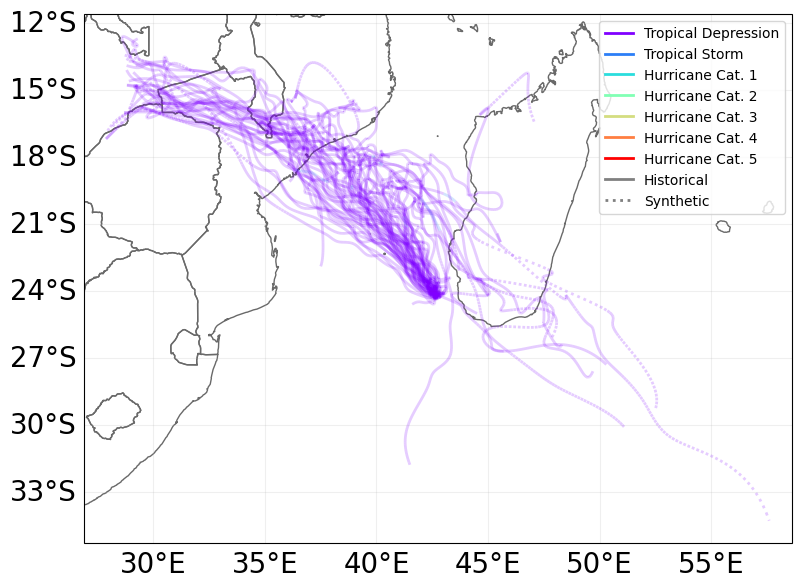

In [20]:
import matplotlib.pyplot as plt

ax = ens_FREDDY_20230306120000.plot(linewidth=0.1, alpha=0.2)

# Optional: adjust figure size or title
fig = ax.get_figure()
fig.set_size_inches(8, 8)  # or any size you want

# Define output path
output_path = "/cluster/home/gespejo/MOZ_struc_plots_Freddy/ensemble_tracks_freddy_20230306120000.png"
fig.savefig(output_path, dpi=300, bbox_inches='tight')

print(f"✅ Saved to: {output_path}")

In [9]:
import pickle
# Define the directory where you want to save the files
save_dir_pickle = '/cluster/work/climate/gespejo/FREDDY_picklefiles/'
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'ens_variables.pkl', 'wb') as file:
    pickle.dump(forecast_variables, file)

In [10]:
ens_variables ['ens_FREDDY_20230311120000'].data[0].attrs['run_datetime']

Timestamp('2023-03-11 12:00:00+0000', tz='UTC')

In [11]:
import copy

# Assuming tc_names is a dictionary in the provided format

# Create a dictionary to store the copied and modified TropCyclone objects
new_tc_names = {}

for tc_name, tc_object in tc_names.items():
    # Get a deep copy of the TropCyclone object
    tc_088_copy = copy.deepcopy(tc_object)
    
    # Handle potential AttributeError
    try:
        # Calculate and update the new intensity data
        new_data = tc_088_copy.intensity.data * 0.88
        tc_088_copy.intensity.data = new_data
        
        # Create a new key with the 'new_' prefix
        new_key = 'new_' + tc_name
        
        # Add the updated TropCyclone object to the new dictionary
        new_tc_names[new_key] = tc_088_copy
    except AttributeError:
        print(f"{tc_name} has no attribute 'intensity'")

# Now, new_tc_names contains the copied and modified TropCyclone objects

In [12]:
new_tc_names ['new_FREDDY_20230306120000'].intensity.data

array([15.85221677, 16.04867754, 15.47675829, ..., 15.48117907,
       15.80565342, 16.09346934])

In [13]:
import pickle

# Define the directory where you want to save the files
save_dir_pickle = '/cluster/work/climate/gespejo/FREDDY_picklefiles/'

# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'forecast_variables.pkl', 'wb') as file:
    pickle.dump(forecast_variables, file)

with open(save_dir_pickle + 'new_tc_names.pkl', 'wb') as file:
    pickle.dump(new_tc_names, file)

In [14]:
## EXPOSURE 

In [15]:
## keep working with the tracks with intensity in Mozambique
##Getting data infrastructure 
import geopandas as gpd
import pandas as pd
from pathlib import Path
import shapely
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix
from datetime import datetime

# on climada_petals branch feature/networks until merged!
# on climada_python develop branch
from climada.util import coordinates as u_coords
from climada.entity.exposures.base import Exposures
from climada.entity.impact_funcs import ImpactFunc, ImpactFuncSet
#from climada.entity import ImpactFunc, ImpactFuncSet
from climada.entity import ImpfTropCyclone
from climada.engine import Impact
from climada.hazard.base import Hazard
from climada.util import lines_polys_handler as u_lp
from climada.util.api_client import Client

#from climada_petals.entity.exposures.openstreetmap import osm_dataloader as osm
from climada_petals.entity.exposures import osm_dataloader as osm
from climada.util import coordinates as u_coords
from climada.hazard.base import Hazard

In [16]:
# general paths & constants
PATH_DATA = '/cluster/work/climate/gespejo/data/infrastructure/'
#PATH_DATA_OSM = '/home/gespejogutierrez/programs/data/openstreetmap/' # path to search for osm.pbf files and to download to if not existing
PATH_DATA_OSM = '/cluster/home/gespejo/osm/osm_bpf/'# path to search for osm.pbf files and to download to if not existing
PATH_DATA_HVMV = PATH_DATA +'power_global/grid.gpkg' # path of this file from gridfinder. needs to be downloaded.
PATH_DATA_PP = PATH_DATA +'power_global/global_power_plant_database.csv' # path of this file from WRI global power plant db. needs to be downloaded.
#PATH_DATA_CT = PATH_DATA +'cell_towers/opencellid_global_1km_int.tif' # path of this file from worldbank open data gridded celltowers. needs to be downloaded.
PATH_DATA_POP = PATH_DATA + 'population/' # path to search for population files and to download to if not existing
PATH_SAVE = '/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_'

In [17]:
import os
from climada.util.coordinates import country_to_iso  # Ensure this function exists

# Define country and ISO3 code
cntry = 'Mozambique'
iso3 = country_to_iso(cntry)  # Converts 'Mozambique' → 'MOZ'

# Search for the correct OSM `.pbf` file dynamically
osm_files = [f for f in os.listdir(PATH_DATA_OSM) if f.endswith("-latest.osm.pbf")]

# Try to find the correct file based on the country name
path_osm_cntry = None
for filename in osm_files:
    if cntry.lower() in filename.lower():  # Match country name in filename
        path_osm_cntry = os.path.join(PATH_DATA_OSM, filename)
        break  # Stop searching after the first match

# If no file was found, raise an error
if not path_osm_cntry:
    raise FileNotFoundError(f"No OSM PBF file found for {cntry} in {PATH_DATA_OSM}")

# Construct paths for other datasets
path_worldpop_cntry_1km = os.path.join(PATH_DATA_POP, f"{iso3.lower()}_ppp_2020_1km_Aggregated_UNadj.tif")
path_worldpop_cntry_100m = os.path.join(PATH_DATA_POP, f"{iso3.lower()}_ppp_2020_UNadj.tif")
path_el_consump_cntry = os.path.join(PATH_DATA, f"power/Electricity consumption per capita - {cntry}.csv")
path_elgen_cntry = os.path.join(PATH_DATA, f"power/Electricity generation by source - {cntry}.csv")
path_el_imp_exp_cntry = os.path.join(PATH_DATA, f"power/Electricity imports vs. exports - {cntry}.csv")
path_save_cntry = PATH_SAVE + f'{iso3}/'
if not os.path.isdir(path_save_cntry):
    os.mkdir(path_save_cntry)

In [18]:
# re-load: the data that I have already proceeed for Mozambique 
gdf_pp = gpd.read_feather(path_save_cntry+'power_plant')
gdf_power = gpd.read_feather(path_save_cntry+'power_component')
gdf_powerlines= gpd.read_feather(path_save_cntry+ 'power_line')
gdf_health = gpd.read_feather(path_save_cntry+ 'health')
gdf_health["latitude"] = gdf_health.geometry.y
gdf_health["longitude"] = gdf_health.geometry.x
gdf_educ = gpd.read_feather(path_save_cntry+'education')
gdf_educ["latitude"] = gdf_educ.geometry.y
gdf_educ["longitude"] = gdf_educ.geometry.x
#gdf_cells= gpd.read_feather(path_save_cntry+'celltower')
gdf_roads = gpd.read_feather(path_save_cntry+'road')

##################### POPULATION 
#from climada.entity.exposures.base import Exposures
#Exposures.from_raster(path_cntry)
gdf_worldpop_MOZ = Exposures.from_raster(path_worldpop_cntry_1km)
#(exposure_pp.gdf.value==0).all()
#exposure_pp_MOZ.gdf
gdf_worldpop_MOZ.set_geometry_points()
#gdf_worldpop_MDG.gdf

In [19]:
###SUBNATIONAL DIVISION 
import geopandas as gpd
geofile_MOZ = '/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ/gadm41_MOZ_shp/gadm41_MOZ_1.shp'
gadm_MOZ = gpd.read_file(geofile_MOZ)

In [20]:
# Rename the 'value' column to 'people'
## This one I should do anyway for the nex 
gdf_worldpop_MOZ.gdf.rename(columns={'value': 'people'}, inplace=True)

In [21]:
def _find_duplicates(overlap_gdf):
    indices_dupl = np.unique([index_right for index_right, index_left in zip(overlap_gdf.index_right, overlap_gdf.index_left)
                    if index_right != index_left])
    indices_dupl = indices_dupl[:int(len(indices_dupl/2))] # only first half of duplicates should be removed!
    return indices_dupl

def _remove_duplicates(orig_gdf, indices_dupl):
    indices_keep = list(set(orig_gdf.index).difference(set(indices_dupl)))
    return orig_gdf.loc[indices_keep]

def find_remove_duplicates(orig_gdf):
    if 'index' in orig_gdf.columns:
        orig_gdf = orig_gdf.drop('index', axis=1)
    overlap_gdf = orig_gdf.sjoin(orig_gdf)
    if 'index_left' not in overlap_gdf.columns:
        overlap_gdf = overlap_gdf.reset_index()
        overlap_gdf = overlap_gdf.rename({'index':'index_left'}, axis=1)  
    indices_dupl = _find_duplicates(overlap_gdf)
    return _remove_duplicates(orig_gdf, indices_dupl) 

In [22]:
gdf_health_MOZ = gdf_health.reset_index(drop=True)
gdf_health_MOZ['geometry'] = gdf_health_MOZ.geometry.buffer(0.001) # ca. 100m buffer in epsg4326; decrease if you think that's too much
gdf_health_MOZ = find_remove_duplicates(gdf_health_MOZ)
gdf_health_MOZ['geometry'] = gdf_health_MOZ.geometry.centroid

/scratch/tmp.27085697.gespejo/ipykernel_2919974/601408166.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf_health_MOZ['geometry'] = gdf_health_MOZ.geometry.buffer(0.001) # ca. 100m buffer in epsg4326; decrease if you think that's too much
/scratch/tmp.27085697.gespejo/ipykernel_2919974/601408166.py:4: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf_health_MOZ['geometry'] = gdf_health_MOZ.geometry.centroid


In [23]:
gdf_educ_MOZ = gdf_educ.reset_index(drop=True)
gdf_educ_MOZ['geometry'] = gdf_educ_MOZ.geometry.buffer(0.001) # ca. 100m buffer in epsg4326; decrease if you think that's too much
gdf_educ_MOZ = find_remove_duplicates(gdf_educ_MOZ)
gdf_educ_MOZ['geometry'] = gdf_educ_MOZ.geometry.centroid
gdf_roads_MOZ = gdf_roads

/scratch/tmp.27085697.gespejo/ipykernel_2919974/3873537115.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf_educ_MOZ['geometry'] = gdf_educ_MOZ.geometry.buffer(0.001) # ca. 100m buffer in epsg4326; decrease if you think that's too much
/scratch/tmp.27085697.gespejo/ipykernel_2919974/3873537115.py:4: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf_educ_MOZ['geometry'] = gdf_educ_MOZ.geometry.centroid


In [24]:
## CLASSIFICATION OF THE HOSPITAL BY LEVELS

In [25]:
# Apply the 'determine_level' function to create the 'levels' column
from climada_petals.hazard.IMP_TRACKFORECAST import determine_level
gdf_health_MOZ['levels'] = gdf_health_MOZ.apply(determine_level, axis=1)

# Remove rows where 'levels' is None
gdf_health_MOZ= gdf_health_MOZ.dropna(subset=['levels'])

In [26]:
# Call the function to remove rows with NaN in the 'name' column
from climada_petals.hazard.IMP_TRACKFORECAST import remove_rows_with_nan
gdf_health_MOZ = remove_rows_with_nan(gdf_health_MOZ)

In [27]:
# Example usage:
# Apply the 'determine_level' function to create the 'levels' column
from climada_petals.hazard.IMP_TRACKFORECAST import determine_level_for_MOZ
gdf_health_MOZ['levels'] = gdf_health_MOZ.apply(determine_level_for_MOZ, axis=1)

In [28]:
import re
import copy
from climada_petals.hazard.IMP_TRACKFORECAST import exposure_from_points, exposure_from_lines, exposure_from_points_with_value, exposure_from_points_pp
from climada_petals.hazard.IMP_TRACKFORECAST import create_exp_dict
# Your exposure calculations
exp_h1_MOZ = exposure_from_points(copy.deepcopy(gdf_health_MOZ), {'TC': 'health_Eberenz'})
exp_h2_MOZ = exposure_from_points(copy.deepcopy(gdf_health_MOZ), {'TC': 'health_deltares'})

##########

exp_ed1_MOZ = exposure_from_points(copy.deepcopy(gdf_educ_MOZ), {'TC': 'health_Eberenz'})
exp_ed2_MOZ = exposure_from_points(copy.deepcopy(gdf_educ_MOZ), {'TC': 'health_deltares'})

##########
exp_rd1_MOZ = exposure_from_lines(copy.deepcopy(gdf_roads_MOZ), {'TC': 'health_Eberenz'}, res=500)
exp_rd2_MOZ = exposure_from_lines(copy.deepcopy(gdf_roads_MOZ), {'TC': 'health_deltares'}, res=500)

###########
exp_pp1_MOZ = exposure_from_points_with_value(copy.deepcopy(path_worldpop_cntry_1km), {'TC': 'cat1'}) 
exp_pp2_MOZ = exposure_from_points_with_value(copy.deepcopy(path_worldpop_cntry_1km), {'TC': 'cat2'}) 
exp_pp3_MOZ = exposure_from_points_with_value(copy.deepcopy(path_worldpop_cntry_1km), {'TC': 'cat3'}) 
exp_pp4_MOZ = exposure_from_points_with_value(copy.deepcopy(path_worldpop_cntry_1km), {'TC': 'cat4'}) 

###########

exp_pp5_MOZ = exposure_from_points_pp(copy.deepcopy(path_worldpop_cntry_1km), {'TC': 'cat1'}) 
exp_pp6_MOZ = exposure_from_points_pp(copy.deepcopy(path_worldpop_cntry_1km), {'TC': 'cat2'}) 
exp_pp7_MOZ = exposure_from_points_pp(copy.deepcopy(path_worldpop_cntry_1km), {'TC': 'cat3'}) 
exp_pp8_MOZ = exposure_from_points_pp(copy.deepcopy(path_worldpop_cntry_1km), {'TC': 'cat4'}) 
##  I defined already LitPop_MOZ at the beginning, but in this case I am addying the function 4 in the exposure 
#exp_h5_MOZ.gdf.impf_ = 4 
# Create and sort the dictionary
exp_dict = create_exp_dict(locals())

2025-03-21 13:43:23,392 - climada.util.lines_polys_handler - WARNING - 5912 lines with a length < 10*resolution were found. Each of these lines is disaggregate to one point. Reaggregatint values will thus likely lead to overestimattion. Consider chosing a smaller resolution or filter out the short lines. 
2025-03-21 13:44:00,635 - climada.util.lines_polys_handler - WARNING - 5912 lines with a length < 10*resolution were found. Each of these lines is disaggregate to one point. Reaggregatint values will thus likely lead to overestimattion. Consider chosing a smaller resolution or filter out the short lines. 


In [29]:
###Save exp_dict
with open(save_dir_pickle + 'exp_dict.pkl', 'wb') as file:
    pickle.dump(exp_dict, file)

In [30]:
from climada_petals.hazard.IMP_TRACKFORECAST import make_impfset
impf_set_tc = make_impfset(ImpFuncsCIWindMoz())
impf_set_tc

In [31]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
imph1 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_health_df = copy.deepcopy(gdf_health_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    impact_var_name1 = f'imph1_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    impact1_obj = Impact()
    impact1_obj.calc(eval(f'exp_h1_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    imph1[impact_var_name1] = impact1_obj

2025-03-21 13:45:04,638 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:04,679 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:04,717 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:04,751 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:04,784 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:04,818 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [32]:
imph1 ['imph1_MOZ_FREDDY_20230306120000'].imp_mat.data

array([0.03369813, 0.05007279, 0.0324393 , ..., 0.00435334, 0.00172127,
       0.00182885])

In [33]:
import copy
from climada.engine import Impact

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
imph2 = {}

# Iterate through track variables in new_tc_names
for track_name_variable in new_tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_health_df = copy.deepcopy(gdf_health_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Access the track object from new_tc_names dictionary
    track_obj = new_tc_names[track_name_variable]

    # Create Impact objects and calculate impacts
    impact_var_name2 = f'imph2_{country_code}_{track_name_variable}'

    # Initialize and calculate the Impact object
    impact2_obj = Impact()
    impact2_obj.calc(eval(f'exp_h2_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the imph2 dictionary
    imph2[impact_var_name2] = impact2_obj

2025-03-21 13:45:04,867 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:04,902 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:04,936 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:04,969 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:05,003 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:05,036 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [34]:
## educational impacts

In [35]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
ed1 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_educ_df = copy.deepcopy(gdf_educ_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    imp_edu1 = f'ed1_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    imp_edu1_obj = Impact()
    imp_edu1_obj.calc(eval(f'exp_ed1_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    ed1[imp_edu1] = imp_edu1_obj

2025-03-21 13:45:05,084 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:05,116 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:05,147 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:05,177 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:05,208 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:05,238 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [36]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
ed2 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in new_tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_educ_df = copy.deepcopy(gdf_educ_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = new_tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    imp_edu2 = f'ed2_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    imp_edu2_obj = Impact()
    imp_edu2_obj.calc(eval(f'exp_ed2_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    ed2[imp_edu2] = imp_edu2_obj

2025-03-21 13:45:05,276 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:05,308 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:05,339 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:05,370 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:05,400 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:05,431 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [37]:
## Roads

In [38]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
rd1 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_roads_df = copy.deepcopy(gdf_roads_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    imp_rd1 = f'rd1_{country_code}_{track_name_variable}'  # Customized name for impact1
    
     # Initialize and calculate the Impact object
    imp_rd1_obj = Impact()
    imp_rd1_obj.calc(eval(f'exp_rd1_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    #imp_rd1_obj = u_lp.impact_pnt_agg(imp_rd1_obj,  eval(f'exp_rd1_{country_code}').gdf, u_lp.AggMethod.SUM)
    
    # Add the impact object to the dictionary with its name as the key
    rd1[imp_rd1] = imp_rd1_obj

2025-03-21 13:45:05,483 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:07,337 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:09,167 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:10,948 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:12,858 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:14,810 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [39]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
rd2 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in new_tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_roads_df = copy.deepcopy(gdf_roads_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = new_tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    imp_rd2 = f'rd2_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    imp_rd2_obj = Impact()
    imp_rd2_obj.calc(eval(f'exp_rd2_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    #imp_rd2_obj = u_lp.impact_pnt_agg(imp_rd2_obj,  eval(f'exp_rd2_{country_code}').gdf, u_lp.AggMethod.SUM)
    
    # Add the impact object to the dictionary with its name as the key
    rd2[imp_rd2] = imp_rd2_obj

2025-03-21 13:45:16,729 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:18,920 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:21,095 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:23,276 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:25,672 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:28,111 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [40]:
rd2 ['rd2_MOZ_new_FREDDY_20230306120000'].at_event/500

array([2.35884917e+03, 7.44571556e+03, 3.37472574e+01, 1.98837471e+04,
       4.44689128e+04, 4.63794793e+04, 6.11771639e+02, 5.96863443e+01,
       1.56984973e+03, 6.69841229e+03, 3.89007023e+04, 3.95704951e+04,
       4.64963758e+04, 5.25315033e+04, 2.73854959e+03, 9.05322432e+03,
       0.00000000e+00, 5.25596841e+03, 3.40341478e+04, 7.56237029e+03,
       2.25062919e+02, 4.90578617e+03, 3.26867107e+04, 6.81527010e+03,
       4.62225725e+03, 6.39830242e+04, 5.27313252e+04, 1.47403622e+04,
       3.84542201e+01, 2.64257612e+03, 5.47956937e+03, 3.51492947e+04,
       0.00000000e+00, 3.80004228e+04, 4.34607723e+04, 1.37690285e+04,
       3.43987983e+04, 2.04265044e+04, 2.22772652e+04, 2.98930712e+04,
       1.47287835e+03, 4.29673233e+03, 1.84440331e+04, 3.86354667e+04,
       2.92096994e+04, 1.91132077e+04, 2.29463786e+04, 1.97887233e+03,
       0.00000000e+00, 2.99217909e+04, 2.41766136e+04])

In [41]:
## people impact

In [42]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
impp1 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_worldpop_df = copy.deepcopy(gdf_worldpop_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    impact_pp_name1 = f'impp1_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    impact_pp1_obj = Impact()
    impact_pp1_obj.calc(eval(f'exp_pp1_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    impp1[impact_pp_name1] = impact_pp1_obj

2025-03-21 13:45:30,584 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:38,888 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:46,982 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:45:54,978 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:46:03,124 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:46:11,217 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [43]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
impp2 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_worldpop_df = copy.deepcopy(gdf_worldpop_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    impact_pp_name2 = f'impp2_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    impact_pp2_obj = Impact()
    impact_pp2_obj.calc(eval(f'exp_pp2_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    impp2[impact_pp_name2] = impact_pp2_obj

2025-03-21 13:46:19,040 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:46:27,017 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:46:34,974 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:46:43,088 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:46:51,116 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:46:59,184 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [44]:
impp2

{'impp2_MOZ_FREDDY_20230306120000': <climada.engine.impact.Impact at 0x150d1d05c110>,
 'impp2_MOZ_FREDDY_20230307120000': <climada.engine.impact.Impact at 0x150c8c78e9d0>,
 'impp2_MOZ_FREDDY_20230308120000': <climada.engine.impact.Impact at 0x150cc96d71d0>,
 'impp2_MOZ_FREDDY_20230309120000': <climada.engine.impact.Impact at 0x150d2c506b50>,
 'impp2_MOZ_FREDDY_20230310120000': <climada.engine.impact.Impact at 0x150d3645d650>,
 'impp2_MOZ_FREDDY_20230311120000': <climada.engine.impact.Impact at 0x150d08b21510>}

In [45]:
impp2 ['impp2_MOZ_FREDDY_20230306120000'].imp_mat.data

array([0.06780189, 0.06780189, 0.06780189, ..., 0.18530613, 0.18530613,
       0.18530613])

In [46]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
impp3 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_worldpop_df = copy.deepcopy(gdf_worldpop_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    impact_pp_name3 = f'impp3_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    impact_pp3_obj = Impact()
    impact_pp3_obj.calc(eval(f'exp_pp3_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    impp3[impact_pp_name3] = impact_pp3_obj

2025-03-21 13:47:07,039 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:47:15,138 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:47:23,164 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:47:31,139 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:47:39,136 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:47:47,152 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [47]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
impp4 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_worldpop_df = copy.deepcopy(gdf_worldpop_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    impact_pp_name4 = f'impp4_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    impact_pp4_obj = Impact()
    impact_pp4_obj.calc(eval(f'exp_pp4_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    impp4[impact_pp_name4] = impact_pp4_obj

2025-03-21 13:47:54,980 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:48:03,049 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:48:11,066 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:48:19,035 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:48:27,069 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:48:35,124 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [48]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
impp5 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_worldpop_df = copy.deepcopy(gdf_worldpop_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    impact_pp_name5 = f'impp5_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    impact_pp5_obj = Impact()
    impact_pp5_obj.calc(eval(f'exp_pp5_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    impp5[impact_pp_name5] = impact_pp5_obj

2025-03-21 13:48:43,059 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:48:50,808 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:48:58,374 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:49:05,911 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:49:13,573 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:49:21,190 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [49]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
impp6 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_worldpop_df = copy.deepcopy(gdf_worldpop_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    impact_pp_name6 = f'impp6_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    impact_pp6_obj = Impact()
    impact_pp6_obj.calc(eval(f'exp_pp6_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    impp6[impact_pp_name6] = impact_pp6_obj

2025-03-21 13:49:28,833 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:49:36,373 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:49:43,959 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:49:51,423 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:49:58,991 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:50:06,603 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [50]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
impp7 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_worldpop_df = copy.deepcopy(gdf_worldpop_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    impact_pp_name7 = f'impp7_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    impact_pp7_obj = Impact()
    impact_pp7_obj.calc(eval(f'exp_pp7_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    impp7[impact_pp_name7] = impact_pp7_obj

2025-03-21 13:50:14,293 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:50:21,920 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:50:29,501 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:50:37,151 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:50:44,820 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:50:52,591 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [51]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
impp8 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_worldpop_df = copy.deepcopy(gdf_worldpop_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    impact_pp_name8 = f'impp8_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    impact_pp8_obj = Impact()
    impact_pp8_obj.calc(eval(f'exp_pp8_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    impp8[impact_pp_name8] = impact_pp8_obj

2025-03-21 13:51:00,159 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:51:07,815 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:51:15,401 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:51:22,853 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:51:30,405 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2025-03-21 13:51:37,999 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [52]:
with open(save_dir_pickle + 'imph1.pkl', 'wb') as file:
    pickle.dump(imph1, file)

In [53]:
with open(save_dir_pickle + 'ed1.pkl', 'wb') as file:
    pickle.dump(ed1, file)

In [54]:
# Save in pickle files
with open(save_dir_pickle + 'imph2.pkl', 'wb') as file:
    pickle.dump(imph2, file)
with open(save_dir_pickle + 'ed2.pkl', 'wb') as file:
    pickle.dump(ed2, file)
with open(save_dir_pickle + 'rd2.pkl', 'wb') as file:
    pickle.dump(rd2, file)
with open(save_dir_pickle + 'impp1.pkl', 'wb') as file:
    pickle.dump(impp1, file)
with open(save_dir_pickle + 'impp2.pkl', 'wb') as file:
    pickle.dump(impp2, file)
with open(save_dir_pickle + 'impp3.pkl', 'wb') as file:
    pickle.dump(impp3, file)
with open(save_dir_pickle + 'impp5.pkl', 'wb') as file:
    pickle.dump(impp5, file)
with open(save_dir_pickle + 'impp6.pkl', 'wb') as file:
    pickle.dump(impp6, file)
with open(save_dir_pickle + 'impp7.pkl', 'wb') as file:
    pickle.dump(impp7, file)

In [59]:
## CALCULATING THE MEAN IMPACT BY EXPOSURE

In [55]:
from climada_petals.hazard.IMP_TRACKFORECAST import calc_mean_for_impdict
mimpacts_all = {}  # Store all mean impacts here

# Iterate through the dictionaries and calculate the mean impacts
for prefix in ['imph','ed','rd', 'impp']:  # Use a list to iterate through both prefixes
    for i in range(1, 9):  # i will take values 1 through 3
        impact_dict_name = f"{prefix}{i}"  # Construct the name of the impact dictionary
        try:
            impact_dict = globals()[impact_dict_name]  # Retrieve the dictionary from globals
        except KeyError:
            print(f"Warning: {impact_dict_name} not found.")
            continue  # Skip to the next iteration if this impact dict is not found
        
        # Calculate the mean impacts and store them in the mimpacts_all dictionary
        mimpacts_all[impact_dict_name] = calc_mean_for_impdict(impact_dict)

In [56]:
mimpacts_all ['impp2'] ['impp2_MOZ_FREDDY_20230306120000']

array([0., 0., 0., ..., 0., 0., 0.])

In [57]:
with open(save_dir_pickle + 'mimpacts_all.pkl', 'wb') as file:
    pickle.dump(mimpacts_all, file)

In [58]:
######add all of them at once in a dictionary 
from climada_petals.hazard.IMP_TRACKFORECAST import calc_imp_overallexp
timpacts_all = {}  # Store all mean impacts here

# Iterate through the dictionaries and calculate the total impacts
for prefix in ['imph','ed','rd', 'impp']:  # Use a list to iterate through both prefixes
    for i in range(1, 9):  # i will take values 1 through 5
        imph_dict_name = f"{prefix}{i}"  # Construct the name of the imph dictionary
        try:
            imph_dict = globals()[imph_dict_name]  # Retrieve the dictionary from globals
        except KeyError:
            print(f"Warning: {imph_dict_name} not found.")
            continue  # Skip to the next iteration if this imph dict is not found
    
        # Calculate the mean impacts and store them in the all_mean_impacts dictionary
        timpacts_all[imph_dict_name] = calc_imp_overallexp(imph_dict)

In [59]:
with open(save_dir_pickle + 'timpacts_all.pkl', 'wb') as file:
    pickle.dump(timpacts_all, file)

In [60]:
### IT RENAMES ALL THE KEYS IN 5 DAYS ....  
# New key names in order
new_keys = ['5 days','4 days', '3 days', '2 days', '1 day', 'landfall']

# Renaming keys for each dictionary inside timpacts_all
for category in timpacts_all:
    timpacts_all[category] = dict(zip(new_keys, timpacts_all[category].values()))

In [61]:
### TOTAL IMPACT BY LEAD TIME

In [62]:
timpacts_all_imph2 = timpacts_all['imph2']

In [63]:
# Calculate mean and standard deviation for each key
# Define a mapping from keys to more readable lead time names
from scipy import stats

lead_time = {
    'imph2_MOZ_new_Idai_20190310120000': '4 days',
    'imph2_MOZ_new_Idai_20190311120000': '3 days',
    'imph2_MOZ_new_Idai_20190312120000': '2 days',
    'imph2_MOZ_new_Idai_20190313120000': '1 day',
    'imph2_MOZ_new_Idai_20190314120000': 'landfall'}
results = []
for key, values in timpacts_all_imph2.items():
    mean_value = np.mean(values)
    std_dev = np.std(values)
    skewness = stats.skew(values)

    readable_lead_time = lead_time.get(key, key)  # Use the mapping
    results.append([readable_lead_time, mean_value, std_dev, skewness])

# Creating a DataFrame from the results
results_df = pd.DataFrame(results, columns=['Lead Time', 'Mean', 'Standard Deviation', 'Skewness'])

results_df

,Lead Time,Mean,Standard Deviation,Skewness
0,5 days,36.528409,31.521647,0.288985
1,4 days,29.381549,25.846291,0.568270
2,3 days,22.399203,19.609568,1.166706
3,2 days,50.736672,18.966749,2.003000
4,1 day,56.573821,14.986870,0.807810
5,landfall,47.236891,13.302790,0.521427


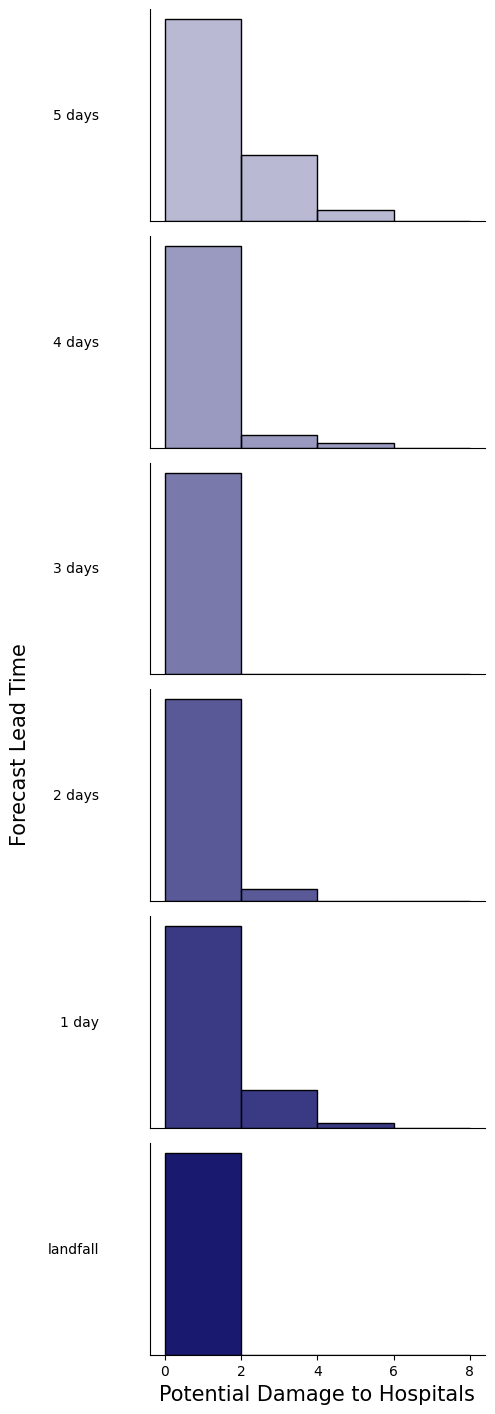

In [64]:
import seaborn as sns
import matplotlib.pyplot as plt

# Make sure nrows matches the number of lead times
lead_times = ['5 days', '4 days', '3 days', '2 days', '1 day', 'landfall']
nrows = len(lead_times)  # Ensure it dynamically adjusts
fig, axes = plt.subplots(nrows, 1, figsize=(5, 15))  # One column of plots

# Define the color for the histograms
dark_blue = "midnightblue"  # Dark blue color

for i, lead_time in enumerate(lead_times):
    # Calculate the alpha as a linear interpolation from 0.3 to 1 over the histograms
    alpha = 0.3 + (i / (nrows - 1) * 0.7)
    
    # Histogram for imph1
    sns.histplot(timpacts_all['imph1'][lead_time], ax=axes[i],
                 bins=[0, 2, 4, 6, 8],
                 color=dark_blue, alpha=alpha)
    
    # Remove x-axis labels for all but the last plot
    if i < nrows - 1:
        axes[i].set_xlabel('')
        axes[i].tick_params(axis='x', which='both', bottom=False, labelbottom=False)
    else:
        axes[i].set_xlabel('Potential Damage to Hospitals', fontsize=15)
        axes[i].tick_params(axis='x', which='both', bottom=True, labelbottom=True)

    # Remove y-axis labels for all plots
    axes[i].set_ylabel('')
    
    # Add the lead times as text on the far left
    axes[i].text(-0.15, 0.5, lead_time, transform=axes[i].transAxes,
                 ha='right', va='center')

    # Show y-axis line only on the leftmost side
    axes[i].spines['left'].set_visible(True)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)
    # Show x-axis line for all plots
    axes[i].spines['bottom'].set_visible(True)

# Set the y-axis to have no ticks
plt.setp(axes, yticks=[])

# Set a common y-axis title aligned centrally with the figure
fig.text(0.02, 0.5, 'Forecast Lead Time', va='center', rotation='vertical', fontsize=15)

# Adjust layout with padding to provide space for common axis labels
plt.tight_layout(rect=[0.05, 0.05, 1, 1])

plt.show()

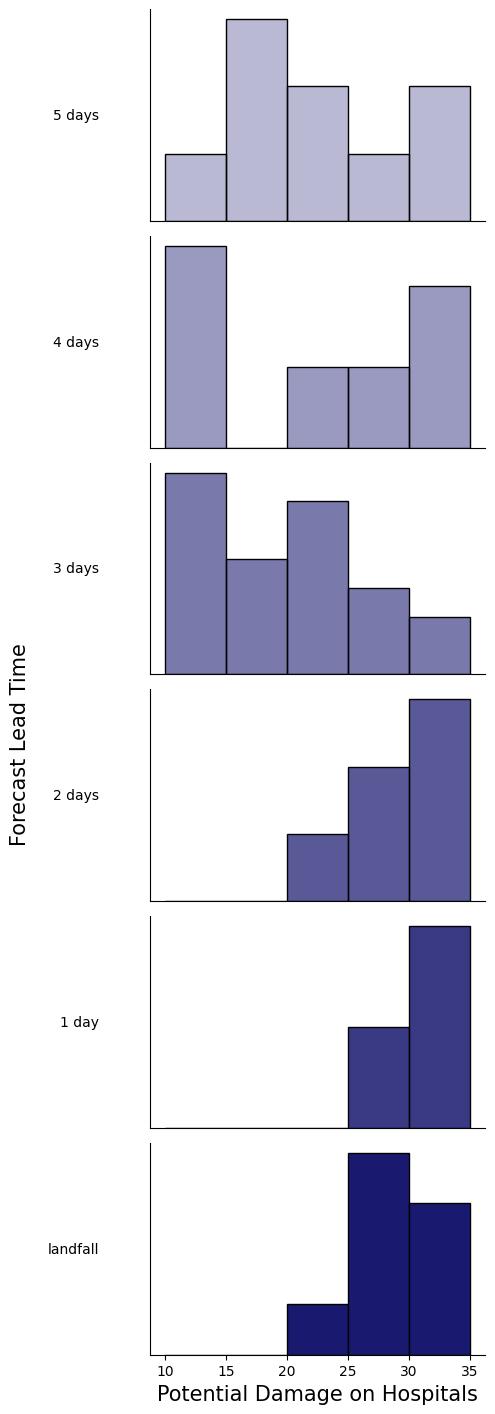

In [72]:
import seaborn as sns
import matplotlib.pyplot as plt

# Make sure nrows matches the number of lead times
lead_times = ['5 days', '4 days', '3 days', '2 days', '1 day', 'landfall']
nrows = len(lead_times)  # Set nrows dynamically to avoid mismatches
fig, axes = plt.subplots(nrows, 1, figsize=(5, 15))  # One column of plots

# Define the color for the histograms
dark_blue = "midnightblue"  # Dark blue color

for i, lead_time in enumerate(lead_times):
    # Calculate the alpha as a linear interpolation from 0.3 to 1 over the histograms
    alpha = 0.3 + (i / (nrows - 1) * 0.7)
    
    # Histogram for imph2
    sns.histplot(timpacts_all['imph2'][lead_time], ax=axes[i],
                 bins=[10, 15, 20, 25, 30, 35],
                 color=dark_blue, alpha=alpha)
    
    # Remove x-axis labels for all but the last plot
    if i < nrows - 1:
        axes[i].set_xlabel('')
        axes[i].tick_params(axis='x', which='both', bottom=False, labelbottom=False)
    else:
        axes[i].set_xlabel('Potential Damage on Hospitals', fontsize=15)
        axes[i].tick_params(axis='x', which='both', bottom=True, labelbottom=True)

    # Remove y-axis labels for all plots
    axes[i].set_ylabel('')
    
    # Add the lead times as text on the far left
    axes[i].text(-0.15, 0.5, lead_time, transform=axes[i].transAxes,
                 ha='right', va='center')

    # Show y-axis line only on the leftmost side
    axes[i].spines['left'].set_visible(True)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)
    # Show x-axis line for all plots
    axes[i].spines['bottom'].set_visible(True)

# Set the y-axis to have no ticks
plt.setp(axes, yticks=[])

# Set a common y-axis title aligned centrally with the figure
fig.text(0.02, 0.5, 'Forecast Lead Time', va='center', rotation='vertical', fontsize=15)

# Adjust layout with padding to provide space for common axis labels
plt.tight_layout(rect=[0.05, 0.05, 1, 1])

plt.show()

In [65]:
## DATAFRAMES OF THE IMPACTS AND CONVERTING EXPOSURES TO DATAFRAMES DICTIONARIES
import pandas as pd
import numpy as np
import copy
from climada.entity import Exposures


# Your impact data
# ... [mimpacts_all definition, assumed to be defined above]
### THIS exp_df_fict is important to join it with the impact data that I am extracting from 
## here from mimpacts_all. In the last step I am converting exposures to dataframes to join it 
## with the impact values, which is important afterwards to join_dfs (data with mean impact plus
## exposure) 

# Converting the impact data into DataFrames
imp_df = {}  # A dictionary to store the impact data DataFrames

for imp_key, impacts in mimpacts_all.items():
    imp_df[imp_key] = pd.DataFrame.from_dict(impacts, orient='index').T

# Converting Exposure objects to DataFrames and saving in a new dictionary
exp_df_dict = {f"{key}_df": pd.DataFrame(copy.deepcopy(exp.gdf)) for key, exp in exp_dict.items()}

In [66]:
import geopandas as gpd

joined_dfs = {}

print("Keys in exp_df_dict:", exp_df_dict.keys())
print("Keys in imp_df:", imp_df.keys())

for prefix in [('exp_h', 'imph'), ('exp_ed','ed'),('exp_rd','rd'),('exp_pp', 'impp')]:
    for i in range(1, 9):  
        exp_key = f'{prefix[0]}{i}_MOZ_df'
        imp_key = f'{prefix[1]}{i}'
        
        print(f"Checking for keys: {exp_key}, {imp_key}")
        
        if exp_key in exp_df_dict and imp_key in imp_df:
            exp_reset = exp_df_dict[exp_key].reset_index(drop=True)
            imp_reset = imp_df[imp_key].reset_index(drop=True)
            
            if exp_reset.shape[0] != imp_reset.shape[0]:
                print(f"Number of rows does not match for {exp_key} and {imp_key}. Skipping.")
                continue
            
            joined_dfs[imp_key] = pd.concat([exp_reset, imp_reset], axis=1) 

Keys in exp_df_dict: dict_keys(['exp_h1_MOZ_df', 'exp_ed1_MOZ_df', 'exp_rd1_MOZ_df', 'exp_pp1_MOZ_df', 'exp_h2_MOZ_df', 'exp_ed2_MOZ_df', 'exp_rd2_MOZ_df', 'exp_pp2_MOZ_df', 'exp_pp3_MOZ_df', 'exp_pp4_MOZ_df', 'exp_pp5_MOZ_df', 'exp_pp6_MOZ_df', 'exp_pp7_MOZ_df', 'exp_pp8_MOZ_df'])
Keys in imp_df: dict_keys(['imph1', 'imph2', 'ed1', 'ed2', 'rd1', 'rd2', 'impp1', 'impp2', 'impp3', 'impp4', 'impp5', 'impp6', 'impp7', 'impp8'])
Checking for keys: exp_h1_MOZ_df, imph1
Checking for keys: exp_h2_MOZ_df, imph2
Checking for keys: exp_h3_MOZ_df, imph3
Checking for keys: exp_h4_MOZ_df, imph4
Checking for keys: exp_h5_MOZ_df, imph5
Checking for keys: exp_h6_MOZ_df, imph6
Checking for keys: exp_h7_MOZ_df, imph7
Checking for keys: exp_h8_MOZ_df, imph8
Checking for keys: exp_ed1_MOZ_df, ed1
Checking for keys: exp_ed2_MOZ_df, ed2
Checking for keys: exp_ed3_MOZ_df, ed3
Checking for keys: exp_ed4_MOZ_df, ed4
Checking for keys: exp_ed5_MOZ_df, ed5
Checking for keys: exp_ed6_MOZ_df, ed6
Checking for keys

# Save in pickle files
with open(save_dir_pickle + 'joined_dfs.pkl', 'wb') as file:
    pickle.dump(joined_dfs, file)

In [ ]:
## EXPOSURES FORMAT 

In [67]:
from climada.entity.exposures import Exposures
from climada_petals.hazard.IMP_TRACKFORECAST import create_and_check_exposures
# Creating exposures_dict to store the created Exposures objects
exposures_dict = {key: create_and_check_exposures(df) for key, df in joined_dfs.items() 
                  if 'latitude' in df.columns and 'longitude' in df.columns}

In [76]:
# IMPACT PLOTTING THEREFORE WE NEED TO EXTRACT IT LONG,LAT,LEVELS. 
## ONCE ALL THE CALCULATION ARE DONE IN DATAFRAMES AND IN EXPOSURES, SUBSET ONLY THE TRACKS TO PLOT ACCORDING TO THE LEAD TIME FORECAST
## AND THE DAY THAT MAKES LANDFALL 

In [68]:
# Define marker shapes for different levels
level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}
# Define a dictionary to map levels to their alpha, edgecolor, and facecolor settings
level_style = {
    1: {'alpha': 0.7, 'edgecolor': 'indigo', 'facecolor': 'indigo', 'size': 5},
    2: {'alpha': 0.7, 'edgecolor': 'mediumslateblue', 'facecolor': 'mediumslateblue', 'size': 10},
    3: {'alpha': 0.7, 'edgecolor': 'darkmagenta', 'facecolor': 'darkmagenta', 'size': 30},  # Darker for level 3
    4: {'alpha': 0.7, 'edgecolor': 'mediumvioletred', 'facecolor': 'mediumvioletred', 'size': 40},    # Darker for level 4
}

In [69]:
import climada.util.plot as u_plot
import climada.util.coordinates as u_coord
import matplotlib.cm as cm_mp
import cartopy.crs as ccrs
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.collections import LineCollection
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D
from climada.util.constants import ONE_LAT_KM, DEF_CRS, CMAP_EXPOSURES
import matplotlib.pyplot as plt
import numpy as np

SAFFIR_SIM_CAT = [17.49, 32.92, 42.7, 49.39, 58.13, 70.48, 1000]
CAT_NAMES = {
    -1: 'Tropical Depression',
    0: 'Tropical Storm',
    1: 'Hurricane Cat. 1',
    2: 'Hurricane Cat. 2',
    3: 'Hurricane Cat. 3',
    4: 'Hurricane Cat. 4',
    5: 'Hurricane Cat. 5',
}


#define the colourmap
color_ranges = [0, 0.02, 0.10, 0.20, 0.50,1.0]  # Add 1.01 to cover the entire range [0, 1]
colors = [(204 / 255, 255 / 255, 102 / 255, 0.1),   # Slightly transparent
    (204 / 255, 255 / 255, 102 / 255,0.9),     # Fully opaque
    (255 / 255, 255 / 255, 0 / 255, 0.9),    # More transparent
    (255 / 255, 153 / 255, 0 / 255, 0.9),
    (255 / 255, 0 / 255, 0 / 255, 0.9)]
# Create a custom colormap from the list of colors
my_cmap = ListedColormap(colors=colors)


# Define marker shapes for different levels
level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}

In [123]:
from datetime import datetime
import pandas as pd
from climada_petals.hazard.IMP_TRACKFORECAST import extract_points_to_plot
# Example usage (Assuming exposures_dict and the necessary key are available and that the gdf attribute of the instances in exposures_dict have the necessary columns.)
#exp_key = 'imph_1'
#date_forecast = '20230306060000'
#event_date = '20230311060000'

#results = perform_calculations(exposures_dict, exp_key, date_forecast, event_date)
p_imph1_plot = extract_points_to_plot(exposures_dict, 'imph1','20230306120000','20230311120000')
p_imph2_plot = extract_points_to_plot(exposures_dict, 'imph2','20230311120000','20230311120000')

Note: Calculating with lead time of 5 days.
Note: The event date and forecast date are the same.


In [124]:
exp_longitude = p_imph2_plot['longitude']
exp_latitude = p_imph2_plot['latitude']
exp_impact = p_imph2_plot['impact_data'] ['impact']
exp_levels = p_imph2_plot['level_data']
lead_time = p_imph2_plot ['lead_time']

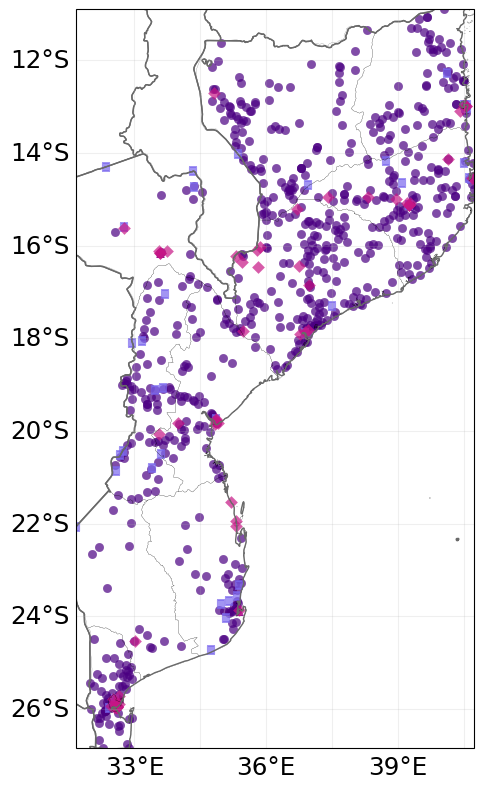

In [81]:
##PLOT EXPOSURE 
from climada_petals.hazard.IMP_TRACKFORECAST import plot_exposure
filename = "/cluster/home/gespejo/MOZ_struc_plots_Freddy/MOZ_Exposures.jpg"
plotting_tracks = plot_exposure(exp_longitude,exp_latitude,exp_impact,exp_levels,filename,filename,gadm_MOZ)

In [82]:
## Plotting tracks 

In [125]:
import climada.util.plot as u_plot
import climada.util.coordinates as u_coord
import matplotlib.cm as cm_mp
import cartopy.crs as ccrs
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.collections import LineCollection
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D
from climada.util.constants import ONE_LAT_KM, DEF_CRS, CMAP_EXPOSURES
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches

SAFFIR_SIM_CAT = [17.49, 32.92, 42.7, 49.39, 58.13, 70.48, 1000]
CAT_NAMES = {
    -1: 'Tropical Depression',
    0: 'Tropical Storm',
    1: 'Hurricane Cat. 1',
    2: 'Hurricane Cat. 2',
    3: 'Hurricane Cat. 3',
    4: 'Hurricane Cat. 4',
    5: 'Hurricane Cat. 5',
}

#define the colourmap
color_ranges = [0, 0.02, 0.10, 0.20, 0.50,1.0]  # Add 1.01 to cover the entire range [0, 1]
colors = [(204 / 255, 255 / 255, 102 / 255, 0.1),   # Slightly transparent
    (204 / 255, 255 / 255, 102 / 255,0.9),     # Fully opaque
    (255 / 255, 255 / 255, 0 / 255, 0.9),    # More transparent
    (255 / 255, 153 / 255, 0 / 255, 0.9),
    (255 / 255, 0 / 255, 0 / 255, 0.9)]
# Create a custom colormap from the list of colors
my_cmap = ListedColormap(colors=colors)

# Create custom legend labels
legend_labels = [
    'No Damage (0.00 - 0.02)',
    'Minor Impact (0.02 - 0.10)',
    'Major Impact (0.10 - 0.20)',
    'Severe Impact (0.20 - 0.50)',
    'Destroyed (0.50 - 1.00)'
]
# Create legend patches based on the colors
legend_patches = [mpatches.Patch(color=colors[i], label=legend_labels[i]) for i in range(len(colors))]

# Define marker shapes for different levels
level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}
# Extracting values from points_to_plot
exp_longitude = p_imph2_plot['longitude']
exp_latitude = p_imph2_plot['latitude']
exp_impact = p_imph2_plot['impact_data'] ['impact']
exp_levels = p_imph2_plot['level_data']
lead_time = p_imph2_plot ['lead_time']

# Define a dictionary to map levels to their alpha, edgecolor, and facecolor settings
level_style = {
    1: {'alpha': 0.7, 'edgecolor': 'indigo', 'facecolor': 'indigo', 'size': 40},
    2: {'alpha': 0.7, 'edgecolor': 'mediumslateblue', 'facecolor': 'mediumslateblue', 'size': 40},
    3: {'alpha': 0.7, 'edgecolor': 'darkmagenta', 'facecolor': 'darkmagenta', 'size': 40},  # Darker for level 3
    4: {'alpha': 0.7, 'edgecolor': 'mediumvioletred', 'facecolor': 'mediumvioletred', 'size': 40},    # Darker for level 4
}

In [84]:
## PLOT WITH TRACKS AND WITHOUT TRACKS MOZAMBIQUIQUE AND ITS HOSPITALS LEVELS

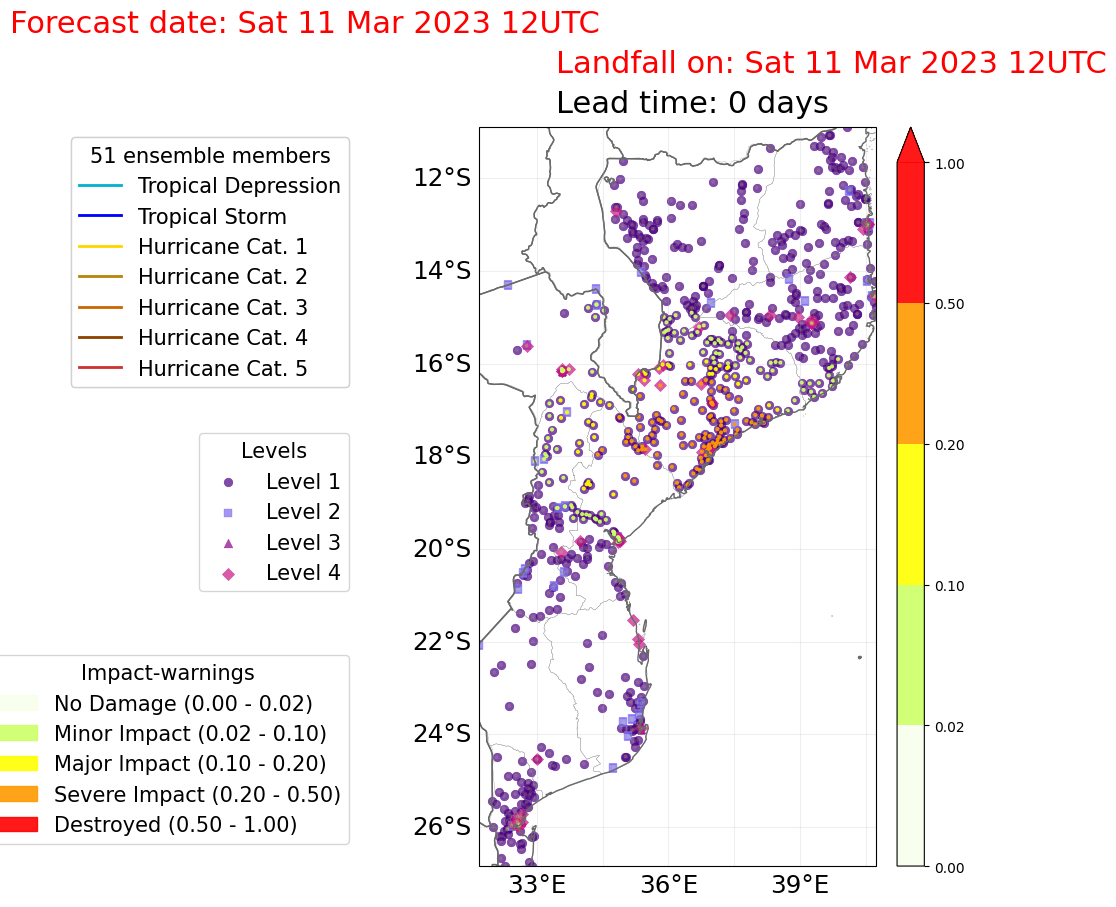

In [85]:
from climada_petals.hazard.IMP_TRACKFORECAST import plot_tracks 
filename= "/cluster/home/gespejo/MOZ_struc_plots_Freddy/MOZ_20230311120000_strucimpforecast_imph2_withouttracks.jpg"
plotting_tracks = plot_tracks(ens_variables ['ens_FREDDY_20230311120000'],
                 exp_longitude,exp_latitude,exp_impact,exp_levels,filename,0,gadm_MOZ,lead_time)

In [86]:
## PLOT WITH TRACKS THE IMPACT WITHOUT LEVELS OF THE HOSPITALS 

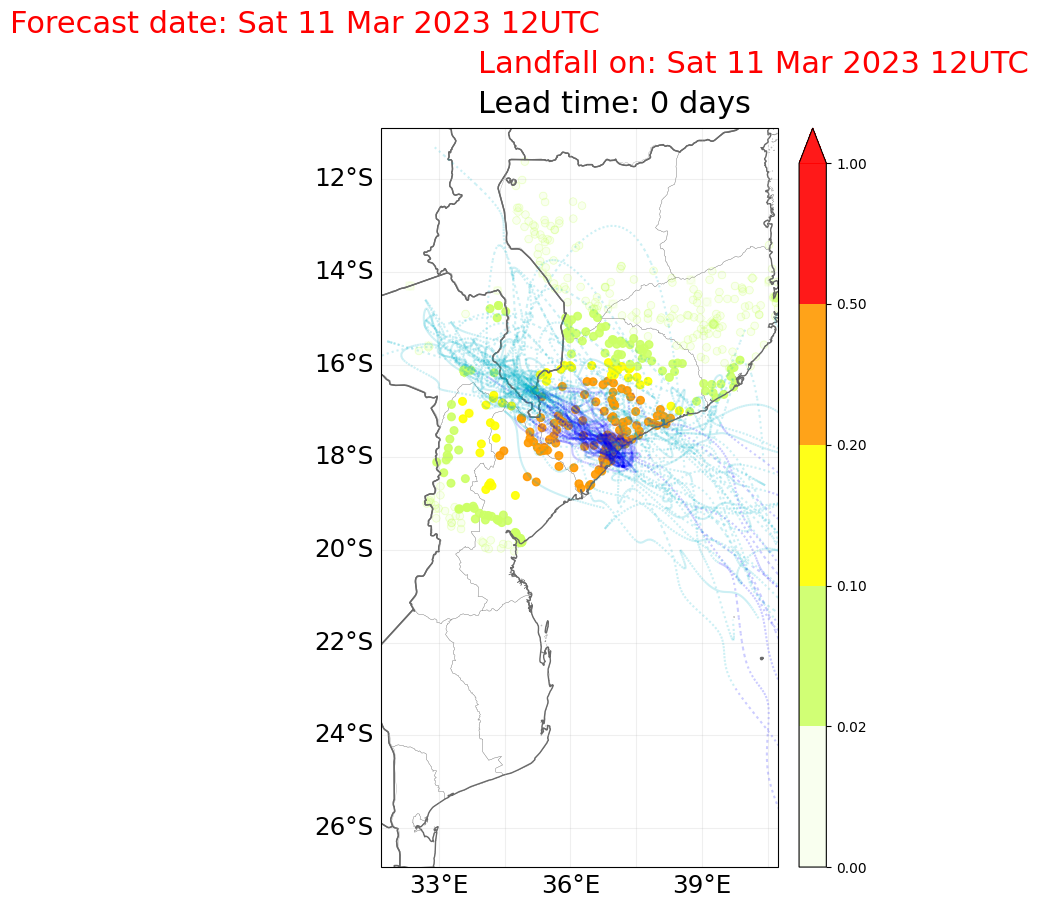

In [87]:
from climada_petals.hazard.IMP_TRACKFORECAST import plot_impact_track 
filename= "/cluster/home/gespejo/MOZ_struc_plots_Freddy/MOZ_20230311120000_strucimpforecast_imph2_impactonly.jpg"
plotting_tracks = plot_impact_track(ens_variables ['ens_FREDDY_20230311120000'],exp_levels,exp_impact,filename,0.2,gadm_MOZ,lead_time)

In [88]:
####PLOT WITHOUT LEGEND

In [112]:
def plot_tracks_nolegend(tc_tracks, exp_lon, exp_lat, exp_value, exp_level, figure_filename, track_alpha, gadm_cntry, lead_time):    
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.colors import BoundaryNorm, ListedColormap
    from matplotlib.collections import LineCollection
    from matplotlib.lines import Line2D
    import cartopy.crs as ccrs
    from mpl_toolkits.axes_grid1 import make_axes_locatable
    from matplotlib.cm import ScalarMappable
    from datetime import timedelta

    color = ['#01B4CC', '#0000ff', '#FFD700', '#B8860B', '#CD6600', '#8B4500', '#CD3333']
    CAT_COLORS = color[0:]
    extent = (exp_lon.min(), exp_lon.max(), exp_lat.min(), exp_lat.max())
    mid_lon = 0.5 * (extent[1] + extent[0])
    proj = ccrs.PlateCarree()
    _, axis, fontsize = u_plot.make_map(proj=proj, figsize=(8, 8), adapt_fontsize=True)
    axis.set_extent(extent, crs=ccrs.PlateCarree())
    u_plot.add_shapes(axis)

    cmap = ListedColormap(colors=CAT_COLORS)
    norm_track = BoundaryNorm([0] + SAFFIR_SIM_CAT, len(SAFFIR_SIM_CAT))

    for track in tc_tracks.data:
        lonlat = np.stack([track.lon.values, track.lat.values], axis=-1)
        lonlat[:, 0] = u_coord.lon_normalize(lonlat[:, 0], center=mid_lon)
        segments = np.stack([lonlat[:-1], lonlat[1:]], axis=1)
        segments = segments[segments[:, 0, 0] * segments[:, 1, 0] >= 0, :, :]
        track_lc = LineCollection(segments, cmap=cmap, norm=norm_track, linestyle=':', alpha=track_alpha)
        track_lc.set_array(track.max_sustained_wind.values)
        axis.add_collection(track_lc)

    # Plot country boundaries
    gadm_cntry.plot(ax=axis, facecolor='none', edgecolor='gray', linewidth=0.2)

    # Create color normalization and scatter map
    norm = BoundaryNorm(color_ranges, my_cmap.N)
    mappable = axis.scatter(exp_lon, exp_lat, s=4, c=exp_value, cmap=my_cmap, norm=norm)

    # Use same colors but plot only selected level markers with different sizes
    scalar_mappable = ScalarMappable(norm=norm, cmap=my_cmap)

    for level in sorted(exp_level['levels'].unique()):
        level_data = exp_level[exp_level['levels'] == level]
        if level_data.empty:
            continue

        marker = level_markers.get(level, 'o')
        marker_size = 6 + (level * 3)  # smaller size for level 1, increasing with level
        facecolors = scalar_mappable.to_rgba(exp_value[level_data.index])

        axis.scatter(
            level_data['longitude'],
            level_data['latitude'],
            marker=marker,
            s=marker_size,
            edgecolor='black',
            facecolor=facecolors,
            linewidths=0.3,
            alpha=0.7
        )

    # Colorbar
    cbax = make_axes_locatable(axis).append_axes('right', size="6.5%", pad=0.1, axes_class=plt.Axes)
    cbar = plt.colorbar(mappable, cax=cbax, orientation='vertical', extend='max')

    # Saffir-Simpson track lines legend (not shown in figure)
    leg_lines = [Line2D([0], [0], color=CAT_COLORS[i_col], lw=2) for i_col in range(len(SAFFIR_SIM_CAT))]
    leg_names = [CAT_NAMES[i_col] for i_col in CAT_NAMES]

    plt.gcf().set_size_inches(14, 8)

    # Add forecast and event date info
    lead_time_str = f"{lead_time} days"
    run_datetime = tc_tracks.data[0].attrs['run_datetime']
    event_time = run_datetime + timedelta(days=lead_time)
    event_time_str = event_time.strftime('%a %d %b %Y %HUTC')
    forecast_date_str = "Forecast date: " + run_datetime.strftime('%a %d %b %Y %HUTC')

    plt.figtext(0.3, 1.1, forecast_date_str, color='black', fontsize=18, ha='left')
    plt.figtext(0.3, 1.05, f'Landfall on: {event_time_str}', color='black', fontsize=18, ha='left')
    plt.figtext(0.3, 1, 'Lead time: ' + lead_time_str, color='k', fontsize=18, ha='left')

    plt.tight_layout()
    plt.savefig(figure_filename, bbox_inches='tight')


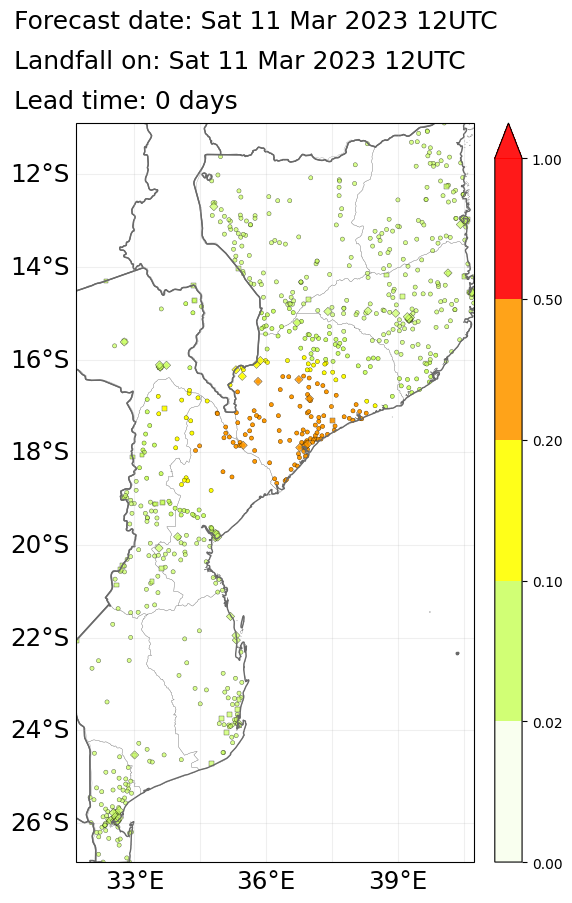

In [126]:
#from climada_petals.hazard.IMP_TRACKFORECAST import plot_tracks_nolegend
filename= "/cluster/home/gespejo/MOZ_struc_plots_Freddy/MOZ_20230311120000_trucimpforecast_nolegend_imph2.jpg"
plotting_tracks_nolegend = plot_tracks_nolegend(ens_variables ['ens_FREDDY_20230311120000'],exp_longitude,exp_latitude,exp_impact,exp_levels,filename,
                                                0, gadm_MOZ, lead_time)

In [90]:
## CALCULATION FOR THE ROADS MEAN IMPACT OVER ALL THE POINTS

In [91]:
from climada_petals.hazard.IMP_TRACKFORECAST import impact_51ens_st
rd1_51ens = impact_51ens_st(rd1, 'rd1','MOZ_FREDDY')
rd2_51ens = impact_51ens_st(rd2, 'rd2','MOZ_new_FREDDY')

In [92]:
##join the points of the road among the 51 ensemble members 

In [93]:
# Example usage
from climada_petals.hazard.IMP_TRACKFORECAST import join_road_exp_51ens
rd1_mimpact = join_road_exp_51ens(rd1_51ens, exp_rd1_MOZ.gdf)
rd2_mimpact = join_road_exp_51ens(rd2_51ens, exp_rd2_MOZ.gdf)

In [94]:
## scale the impact among the road 

In [95]:
# Example usage:
from climada_petals.hazard.IMP_TRACKFORECAST import mimpact_col_scale
mimpact_col_scale(rd2_mimpact, 'mean_impact', 500)
mimpact_col_scale(rd1_mimpact, 'mean_impact', 500)

In [96]:
####PLOT ROAD IMPACTS

In [97]:
import geopandas as gpd
import matplotlib.pyplot as plt  
import matplotlib.cm as cm
from datetime import datetime
from dateutil.parser import parse
import os
def plot_road_impact(rd1_mimpact, gadm_MDG, output_folder, landfall):
    """Function to plot road impact based on forecast data."""
    landfall_date = parse(landfall)

    # Ensure the output folder exists
    os.makedirs(output_folder, exist_ok=True)

    for key, gdf in rd1_mimpact.items():
        figsize = (12, 12)
        fig, ax = plt.subplots(figsize=figsize)

        # Parse the forecast date from the key
        forecast_date = parse(key)
        lead_time_days = (landfall_date - forecast_date).days  # Calculate lead time in days

        # Use the corrected colormap function
        cmap = plt.get_cmap('plasma')  # Using plt.get_cmap() instead of cm.get_cmap()
        cmap.set_under('black', alpha=0.1)

        # Plot administrative boundaries
        gadm_MDG.plot(ax=ax, facecolor='none', edgecolor='gray', linewidth=0.5)

        # Plot 'mean_impact' from the GeoDataFrame
        gdf.plot(column='mean_impact', ax=ax, cmap=cmap, legend=True, vmin=0.01, vmax=1)

        # Adjust layout
        plt.subplots_adjust(top=0.8)

        # Add plot customizations
        plt.suptitle(f"Deltares: TC-Freddy landfall on {landfall_date.strftime('%d %b %Y %H %Z')} UTC", fontsize=22, y=0.89)
        ax.text(-0.1, 1.08, forecast_date.strftime('%a %d %b %Y %H %Z') + " UTC", 
                ha='left', va='top', transform=ax.transAxes, color='red', fontsize=22)
        ax.text(-0.1, 1.04, f"Lead time: {lead_time_days} days", 
                ha='left', va='top', transform=ax.transAxes, color='red', fontsize=22)
        ax.set_axis_off()

        # Save the plot
        output_path = os.path.join(output_folder, f"road_plot_{key}_14032019_deltares.jpg")
        plt.savefig(output_path, bbox_inches='tight', format='jpg')

        plt.close()  # Close the figure to free memory

In [98]:
#from climada_petals.hazard.IMP_TRACKFORECAST import plot_road_impact
plot_road_impact(rd2_mimpact, gadm_MOZ, '/cluster/home/gespejo/MOZ_struc_plots_Freddy/', '20230311120000')

In [99]:
###filter disrupted roads above 0.20 

In [100]:
# Define the threshold value (e.g., 0.20)
from climada_petals.hazard.IMP_TRACKFORECAST import filter_disruptrd_data
threshold = 0.20   ##severe damage

# Call the function to filter "mean_impact" values for all keys
disrupt_rd1 = filter_disruptrd_data(rd1_mimpact, threshold)
disrupt_rd2 = filter_disruptrd_data(rd2_mimpact, threshold)

In [101]:
### CREATE POINTS FOR EVERY CI AND PEOPLE 
from climada_petals.hazard.IMP_TRACKFORECAST import convert_to_geodf
gadm_MOZ_gdf = convert_to_geodf(gadm_MOZ, ['NAME_1', 'geometry'])

In [ ]:
from climada_petals.hazard.IMP_TRACKFORECAST import create_points_geodfs_hfacilities,create_points_geodfs_CI,create_points_geodfs_pp
crs = gadm_MOZ_gdf.crs  # Replace with your actual CRS
points_geo_h1 = create_points_geodfs_hfacilities(imph1, exp_dict['exp_h1_MOZ'].gdf, crs)

In [ ]:
points_geo_ed1 = create_points_geodfs_CI(ed1,exp_dict['exp_ed1_MOZ'].gdf,crs)

In [ ]:
points_geo_h2 = create_points_geodfs_hfacilities(imph2, exp_dict['exp_h2_MOZ'].gdf, crs)

In [ ]:
points_geo_ed2 = create_points_geodfs_CI(ed2,exp_dict['exp_ed2_MOZ'].gdf,crs)

In [ ]:
points_geo_pp5 = create_points_geodfs_pp(impp5,exp_dict['exp_pp5_MOZ'].gdf,crs)

In [104]:
###Adding points for columns

In [105]:
from climada_petals.hazard.IMP_TRACKFORECAST import add_columns_in_geodata
add_columns_in_geodata(points_geo_h1, mimpacts_all, 'imph1')
add_columns_in_geodata(points_geo_h2, mimpacts_all, 'imph2')
add_columns_in_geodata(points_geo_ed1, mimpacts_all, 'ed1')
add_columns_in_geodata(points_geo_ed2, mimpacts_all, 'ed2')
#add_columns_in_geodata(points_geo_pp1, mimpacts_all, 'impp1')
#add_columns_in_geodata(points_geo_pp2, mimpacts_all, 'impp2')
#add_columns_in_geodata(points_geo_pp3, mimpacts_all, 'impp3')
#add_columns_in_geodata(points_geo_pp4, mimpacts_all, 'impp4')
add_columns_in_geodata(points_geo_pp5, mimpacts_all, 'impp5')
#add_columns_in_geodata(points_geo_pp6, mimpacts_all, 'impp6')
#add_columns_in_geodata(points_geo_pp7, mimpacts_all, 'impp7')
#add_columns_in_geodata(points_geo_pp8, mimpacts_all, 'impp8')

In [106]:
points_dfs = {**points_geo_h1, **points_geo_h2, **points_geo_ed1, **points_geo_ed2,
              **points_geo_pp5,**points_geo_pp6}

In [89]:
### Convert my columns in geodataframes 

In [107]:
from climada_petals.hazard.IMP_TRACKFORECAST import conv_col_togdf_hf, conv_col_togdf_st,conv_col_togdf_pp
# Assuming `joined_dfs['imph_4']` and `joined_dfs['imph_5']` are your dataframes
gdfs_imph2 = conv_col_togdf_hf(joined_dfs['imph2'], 'imph2_MOZ_new_FREDDY_')
gdfs_ed2 = conv_col_togdf_st(joined_dfs['ed2'], 'ed2_MOZ_new_FREDDY_')
#gdfs_rd2 = conv_col_togdf_rd(joined_dfs['rd2'], 'rd2_MOZ_Idai_')
gdfs_pp1 = conv_col_togdf_pp(joined_dfs['impp1'], 'impp1_MOZ_FREDDY_')
gdfs_pp2 = conv_col_togdf_pp(joined_dfs['impp2'], 'impp2_MOZ_FREDDY_')
gdfs_pp3 = conv_col_togdf_pp(joined_dfs['impp3'], 'impp3_MOZ_FREDDY_') ## this is with the category 2 therefore not new_Freddy
#gdfs_pp4 = conv_col_togdf_pp(joined_dfs['impp4'], 'impp4_MOZ_Idai_')

In [108]:
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'gdfs_imph2.pkl', 'wb') as file:
    pickle.dump(gdfs_imph2, file)

In [109]:
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'gdfs_ed2.pkl', 'wb') as file:
    pickle.dump(gdfs_ed2, file)

In [110]:
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'gdfs_pp1.pkl', 'wb') as file:
    pickle.dump(gdfs_pp1, file)

In [111]:
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'gdfs_pp2.pkl', 'wb') as file:
    pickle.dump(gdfs_pp2, file)

In [112]:
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'gdfs_pp3.pkl', 'wb') as file:
    pickle.dump(gdfs_pp3, file)

In [96]:
###Spatial join between the hospitals and MOZ for provinces 

In [113]:
from climada_petals.hazard.IMP_TRACKFORECAST import sjoin_gdfs
jd_gdfs_imph2 = sjoin_gdfs(gdfs_imph2, gadm_MOZ_gdf)
jd_gdfs_ed2 = sjoin_gdfs(gdfs_ed2, gadm_MOZ_gdf)
jd_gdfs_pp1 = sjoin_gdfs(gdfs_pp1, gadm_MOZ_gdf)
jd_gdfs_pp2 = sjoin_gdfs(gdfs_pp2, gadm_MOZ_gdf)
jd_gdfs_pp3 = sjoin_gdfs(gdfs_pp3, gadm_MOZ_gdf)
#jd_gdfs_pp4 = sjoin_gdfs(gdfs_pp4, gadm_MOZ_gdf)

In [114]:
# Define the directory where you want to save the files
save_dir_pickle = '/cluster/home/gespejo/FREDDY_picklefiles/'

# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'jd_gdfs_pp1.pkl', 'wb') as file:
    pickle.dump(jd_gdfs_pp1, file)

In [115]:
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'jd_gdfs_pp2.pkl', 'wb') as file:
    pickle.dump(jd_gdfs_pp2, file)

In [116]:
#with open(save_dir_pickle + 'jd_gdfs_pp3.pkl', 'wb') as file:
#    pickle.dump(jd_gdfs_pp3, file)

In [117]:
with open(save_dir_pickle + 'jd_gdfs_ed2.pkl', 'wb') as file:
    pickle.dump(jd_gdfs_ed2, file)

In [118]:
with open(save_dir_pickle + 'jd_gdfs_imph2.pkl', 'wb') as file:
    pickle.dump(jd_gdfs_imph2, file)

In [ ]:
#with open(save_dir_pickle + 'points_dfs.pkl', 'wb') as file:
#    pickle.dump(points_dfs, file)

In [119]:
with open(save_dir_pickle + 'exposures_dict.pkl', 'wb') as file:
    pickle.dump(exposures_dict, file)

In [120]:
with open(save_dir_pickle + 'rd1_mimpact.pkl', 'wb') as file:
    pickle.dump(rd1_mimpact, file)

In [121]:
with open(save_dir_pickle + 'rd2_mimpact.pkl', 'wb') as file:
    pickle.dump(rd2_mimpact, file)

In [122]:
with open(save_dir_pickle + 'disrupt_rd1.pkl', 'wb') as file:
    pickle.dump(disrupt_rd1, file)

In [123]:
with open(save_dir_pickle + 'disrupt_rd2.pkl', 'wb') as file:
    pickle.dump(disrupt_rd2, file)

In [ ]:
###his is counting how many facilities are in risk at leats with values above 0, and also summing up
## However, it is not transfareable to say that the total impact means 10 hospitals disrupted. 

In [124]:
# Example usage:
from climada_petals.hazard.IMP_TRACKFORECAST import hfacilities_inrisk
nh2_risk = hfacilities_inrisk(jd_gdfs_imph2) 
#nh1_risk = hfacilities_inrisk(jd_gdfs_imph1) 
### This is counting how many facilities are in risk at leats with values above 0, and also summing up
## However, it is not transfareable to say that the total impact means 10 hospitals disrupted. 

In [125]:
# Example usage:
from climada_petals.hazard.IMP_TRACKFORECAST import hfacilities_level_nfailure
nh2_c = hfacilities_level_nfailure(jd_gdfs_imph2)
#nh1_c = hfacilities_level_nfailure(jd_gdfs_imph1)

In [126]:
# Example usage:
from climada_petals.hazard.IMP_TRACKFORECAST import hfacilities_impsum_level
nh2 = hfacilities_impsum_level(jd_gdfs_imph2)
#nh1 = hfacilities_impsum_level(jd_gdfs_imph1)

In [127]:
from climada_petals.hazard.IMP_TRACKFORECAST import CI_inrisk
ned2_risk = CI_inrisk(jd_gdfs_ed2)

In [ ]:
## Aggregate impact by regions 

In [ ]:
from climada_petals.hazard.IMP_TRACKFORECAST import aggregate_impact_by_regions_for_all
agg_impact_imph2 = aggregate_impact_by_regions_for_all(points_geo_h2, gadm_MOZ_gdf, imph2)

In [ ]:
agg_impact_ed2 = aggregate_impact_by_regions_for_all(points_geo_ed2, gadm_MOZ_gdf, ed2)

In [ ]:
agg_impact_pp5 = aggregate_impact_by_regions_for_all(points_geo_pp5, gadm_MOZ_gdf, impp5)

In [ ]:
with open(save_dir_pickle + 'agg_impact_imph2.pkl', 'wb') as file:
    pickle.dump(agg_impact_imph2, file)

In [ ]:
with open(save_dir_pickle + 'agg_impact_ed2.pkl', 'wb') as file:
    pickle.dump(agg_impact_ed2, file)

In [ ]:
with open(save_dir_pickle + 'agg_impact_pp5.pkl', 'wb') as file:
    pickle.dump(agg_impact_pp5, file)

In [ ]:
## DISRUPTION

In [1]:
### disruptions 
# Example usage
from climada_petals.hazard.IMP_TRACKFORECAST import filter_disrupted
threshold = 0.20
threshold_cat = 0.10 ##at leats 5 ensemble members hit the point 
disrupt_imph2 = filter_disrupted(jd_gdfs_imph2, threshold)
disrupt_ed2 = filter_disrupted(jd_gdfs_ed2, threshold)
disrupt_pp1 = filter_disrupted(jd_gdfs_pp1, threshold_cat)
disrupt_pp2 = filter_disrupted(jd_gdfs_pp2, threshold_cat)
disrupt_pp3 = filter_disrupted(jd_gdfs_pp3, threshold_cat)
#disrupt_pp4 = filter_disrupted(jd_gdfs_pp4, threshold_cat)

NameError: name 'jd_gdfs_imph2' is not defined

In [ ]:
disrupt_imph2_copy = disrupt_imph2.copy()
disrupt_ed2_copy = disrupt_ed2.copy()
disrupt_pp1_copy = disrupt_pp1.copy()
disrupt_pp2_copy = disrupt_pp2.copy()
disrupt_pp3_copy = disrupt_pp3.copy()
jd_gdfs_pp1_copy = jd_gdfs_pp1.copy()

In [ ]:
with open(save_dir_pickle + 'disrupt_imph2.pkl', 'wb') as file:
    pickle.dump(disrupt_imph2, file)

In [ ]:
with open(save_dir_pickle + 'disrupt_ed2.pkl', 'wb') as file:
    pickle.dump(disrupt_ed2, file)

In [ ]:
with open(save_dir_pickle + 'disrupt_pp1.pkl', 'wb') as file:
    pickle.dump(disrupt_pp1, file)

In [ ]:
with open(save_dir_pickle + 'disrupt_pp2.pkl', 'wb') as file:
    pickle.dump(disrupt_pp2, file)

In [ ]:
with open(save_dir_pickle + 'disrupt_pp3.pkl', 'wb') as file:
    pickle.dump(disrupt_pp3, file)

In [ ]:
#from climada_petals.hazard.IMP_TRACKFORECAST import CI_level_nfailure
#ned2_fail = CI_level_nfailure(jd_gdfs_ed2)

In [ ]:
from climada_petals.hazard.IMP_TRACKFORECAST import get_unique_disrupt_impp1, subset_imppeople

In [ ]:
imp_people_nodisrupted_gadm_cat1 = subset_imppeople(jd_gdfs_pp1_copy,0.1)
imp_people_nodisrupted_gadm_cat1_copy = imp_people_nodisrupted_gadm_cat1.copy()

In [ ]:
with open(save_dir_pickle + 'imp_people_nodisrupted_gadm_cat1_copy.pkl', 'wb') as file:
    pickle.dump(imp_people_nodisrupted_gadm_cat1_copy, file)

In [ ]:
# Create copies of the input dictionaries to preserve original data
#imp_people_cat1_copy = imp_people_cat1.copy()
disrupt_imph2_copy = disrupt_imph2.copy()
disrupt_pp2_copy = disrupt_pp2.copy()

In [ ]:
# Use the function to get the unique points for all keys in disrupt_pp1
disrupt_pp1_unique_dict = get_unique_disrupt_impp1(disrupt_pp1_copy, disrupt_pp2_copy)
disrupt_pp1_unique_dict_copy = disrupt_pp1_unique_dict.copy()

In [ ]:
with open(save_dir_pickle + 'disrupt_pp1_unique_dict.pkl', 'wb') as file:
    pickle.dump(disrupt_pp1_unique_dict, file)

In [ ]:
from climada_petals.hazard.IMP_TRACKFORECAST import get_ppaffected_cat1_nodisrupt
imppeople_nodisrupt_cat1 = get_ppaffected_cat1_nodisrupt(imp_people_nodisrupted_gadm_cat1_copy, disrupt_pp1_copy, disrupt_pp2_copy)
imppeople_nodisrupt_cat1_copy = imppeople_nodisrupt_cat1.copy()

In [ ]:
with open(save_dir_pickle + 'imppeople_nodisrupt_cat1_copy.pkl', 'wb') as file:
    pickle.dump(imppeople_nodisrupt_cat1_copy, file)

In [ ]:
## Nearest Neighbor Method 

In [ ]:
from climada_petals.hazard.IMP_TRACKFORECAST import calculate_nearest_population , cal_nearestpop_disrup

In [ ]:
# Create copies of the input dictionaries to preserve original data
disrupt_imph2_copy = disrupt_imph2.copy()
disrupt_pp1_unique_dict_copy = disrupt_pp1_unique_dict.copy()
disrupt_pp2_copy = disrupt_pp2.copy()

In [ ]:
## PEOPLE AFFECTED WHEN HOSPITALS ARE DISRUPTED
disrupt_imph2_pp1 = cal_nearestpop_disrup(disrupt_imph2_copy, disrupt_pp1_unique_dict_copy)
disrupt_imph2_pp2 = cal_nearestpop_disrup(disrupt_imph2_copy, disrupt_pp2_copy)

In [ ]:
## PEOPLE AFFECTED WHEN SCHOOLS ARE DISRUPTED
disrupt_ed2_pp1 = cal_nearestpop_disrup(disrupt_ed2_copy, disrupt_pp1_unique_dict_copy)
disrupt_ed2_pp2 = cal_nearestpop_disrup(disrupt_ed2_copy, disrupt_pp2_copy)

In [ ]:
### people affected whe n road is dirupted

In [ ]:
disrupt_rd2_copy = disrupt_rd2.copy()
#disrupt_rd2_pp1 = calculate_pp_byroaddisrup(disrupt_rd2_copy, disrupt_pp1_copy, radius_km=2)

In [ ]:
# Example usage
from climada_petals.hazard.IMP_TRACKFORECAST import assign_province_to_roads
disrupt_rd2_copy = assign_province_to_roads(disrupt_rd2_copy, gadm_MOZ_gdf)

In [ ]:
from climada_petals.hazard.IMP_TRACKFORECAST import calculate_pp_byroaddisrup

In [ ]:
disrupt_rd2_copy ['20230306120000']

In [ ]:
disrupt_pp1_copy ['impp1_MOZ_FREDDY_20230306120000']

In [2]:
disrupt_rd2_pp1 = calculate_pp_byroaddisrup(disrupt_rd2_copy, disrupt_pp1_copy, radius_km=2)

NameError: name 'disrupt_rd2_copy' is not defined

In [195]:
#disrupt_rd2_pp2 = calculate_pp_byroaddisrup(disrupt_rd2_copy, disrupt_pp2_copy, radius_km=2)

ValueError: Expected 2D array, got 1D array instead:
array=[].
Reshape your data either using array.reshape(-1, 1) if your data has a single feature or array.reshape(1, -1) if it contains a single sample.

In [543]:
### CALCULATE THE PEOPLE DIRECT FORM THE POPULATION AND NOT OF THE DISRUPTED PEOPLE 

In [ ]:
#PLOT DISRUPT_PP1, DISRUPT_PP2 AND PEOPLE AFFECTED FOR CATEGORY1 AND NOT FOR DISRUPTION, HOSPITALS AS WELL DISRUPTED

In [198]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import datetime
import os

people_disrupt_nodisrupt_cat_folder = '/cluster/home/gespejo/MOZ_struc_plots_Freddy'

# Loop through the keys in disrupt_pp1_unique_dict
for key in disrupt_pp1_unique_dict.keys():
    date_key = key.split('_')[-1]
    key_pp2 = f'impp2_MOZ_FREDDY_{date_key}'
    key_imph2 = f'imph2_MOZ_new_FREDDY_{date_key}'
    key_imppeople = f'impp1_MOZ_FREDDY_{date_key}'

    if key_pp2 in disrupt_pp2 and key_imph2 in disrupt_imph2 and key_imppeople in imppeople_nodisrupt_cat1_copy:
        disrupt_pp1_unique_gdf = disrupt_pp1_unique_dict[key]
        disrupt_imph2_df = disrupt_imph2[key_imph2]
        imppeople_nodisrupt_cat1_copy_df = imppeople_nodisrupt_cat1_copy[key_imppeople]

        # Check if each GeoDataFrame has data and print a message if not
        if disrupt_pp1_unique_gdf.empty:
            print(f" 'disrupt_pp1_unique_gdf' is empty for {date_key}, skipping this layer.")
        if disrupt_imph2_df.empty:
            print(f" 'disrupt_imph2_df' is empty for {date_key}, skipping this layer.")
        if imppeople_nodisrupt_cat1_copy_df.empty:
            print(f" 'imppeople_nodisrupt_cat1_copy_df' is empty for {date_key}, skipping this layer.")

        # Check if disrupt_pp2_df has data
        disrupt_pp2_df = disrupt_pp2[key_pp2]
        disrupt_pp2_df = disrupt_pp2_df[disrupt_pp2_df['imp_people'] > 1]
        disrupt_pp2_has_data = not disrupt_pp2_df.empty
        if not disrupt_pp2_has_data:
            print(f" 'disrupt_pp2_df' is empty for {date_key}, skipping this layer.")

        # Skip plotting if all datasets are empty
        if all([df.empty for df in [disrupt_pp1_unique_gdf, disrupt_imph2_df, imppeople_nodisrupt_cat1_copy_df]]) and not disrupt_pp2_has_data:
            print(f" All layers are empty for {date_key}. Skipping plot.")
            continue

        # Spatial joins
        if not disrupt_pp1_unique_gdf.empty:
            disrupt_pp1_unique_gdf = gpd.sjoin(disrupt_pp1_unique_gdf, gadm_MOZ_gdf, how="inner", predicate="within")
        if not disrupt_imph2_df.empty:
            disrupt_imph2_df = gpd.sjoin(disrupt_imph2_df, gadm_MOZ_gdf, how="inner", predicate="within")
        if not imppeople_nodisrupt_cat1_copy_df.empty:
            imppeople_nodisrupt_cat1_copy_df = gpd.sjoin(imppeople_nodisrupt_cat1_copy_df, gadm_MOZ_gdf, how="inner", predicate="within")
        if disrupt_pp2_has_data:
            disrupt_pp2_df = gpd.sjoin(disrupt_pp2_df, gadm_MOZ_gdf, how="inner", predicate="within")

        # Plot the available data
        parsed_date = datetime.datetime.strptime(date_key, '%Y%m%d%H%M%S')
        formatted_date = parsed_date.strftime('forecast date: %a %d %B %Y %H UTC')

        greens_cmap = plt.cm.Greens(np.linspace(0.2, 1, 256))
        oranges_cmap = plt.cm.Oranges(np.linspace(0.2, 1, 256))
        purples_cmap = plt.cm.Purples(np.linspace(0.2, 1, 256))

        new_greens_cmap = mcolors.ListedColormap(greens_cmap)
        new_oranges_cmap = mcolors.ListedColormap(oranges_cmap)
        new_purples_cmap = mcolors.ListedColormap(purples_cmap)

        fig, ax = plt.subplots(figsize=(10, 10))
        gadm_MOZ_gdf.plot(ax=ax, color='white', edgecolor='black')

        # Plot only non-empty datasets
        if not disrupt_pp1_unique_gdf.empty:
            disrupt_pp1_unique_gdf.plot(ax=ax, column='imp_people', cmap=new_greens_cmap, legend=False, edgecolor='none', markersize=40)
        if disrupt_pp2_has_data:
            disrupt_pp2_df.plot(ax=ax, column='imp_people', cmap=new_oranges_cmap, legend=False, edgecolor='none', markersize=40)
        if not imppeople_nodisrupt_cat1_copy_df.empty:
            imppeople_nodisrupt_cat1_copy_df.plot(ax=ax, column='imp_people', cmap=new_purples_cmap, legend=False, edgecolor='none', markersize=40)

        # Plot health facilities by level if available
        if not disrupt_imph2_df.empty:
            level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}
            level_style = {
                1: {'alpha': 0.7, 'edgecolor': 'indigo', 'facecolor': 'indigo', 's': 10},
                2: {'alpha': 0.7, 'edgecolor': 'mediumslateblue', 'facecolor': 'mediumslateblue', 's': 10},
                3: {'alpha': 0.7, 'edgecolor': 'darkmagenta', 'facecolor': 'darkmagenta', 's': 10},
                4: {'alpha': 0.7, 'edgecolor': 'mediumvioletred', 'facecolor': 'mediumvioletred', 's': 10},
            }
            for level in disrupt_imph2_df['levels'].unique():
                level_df = disrupt_imph2_df[disrupt_imph2_df['levels'] == level]
                ax.scatter(
                    level_df['longitude'], level_df['latitude'],
                    marker=level_markers[level],
                    label=f'Health Facility Level {level}',
                    **level_style[level]
                )

        ax.set_xlim([32, 42])
        ax.set_ylim([-20, -13.5])
        ax.set_title(formatted_date, fontsize=15)

        # Dynamic colorbars only if data exists
        if not disrupt_pp1_unique_gdf.empty:
            sm1 = plt.cm.ScalarMappable(cmap=new_greens_cmap, norm=plt.Normalize(
                vmin=disrupt_pp1_unique_gdf['imp_people'].min(), vmax=disrupt_pp1_unique_gdf['imp_people'].max()))
            fig.colorbar(sm1, ax=ax, orientation='horizontal', fraction=0.02, pad=0.07).set_label('People disrupted cat.1')

        if not imppeople_nodisrupt_cat1_copy_df.empty:
            sm3 = plt.cm.ScalarMappable(cmap=new_purples_cmap, norm=plt.Normalize(
                vmin=imppeople_nodisrupt_cat1_copy_df['imp_people'].min(), vmax=imppeople_nodisrupt_cat1_copy_df['imp_people'].max()))
            fig.colorbar(sm3, ax=ax, orientation='horizontal', fraction=0.02, pad=0.05).set_label('People direct affected')

        if disrupt_pp2_has_data:
            sm2 = plt.cm.ScalarMappable(cmap=new_oranges_cmap, norm=plt.Normalize(
                vmin=disrupt_pp2_df['imp_people'].min(), vmax=disrupt_pp2_df['imp_people'].max()))
            fig.colorbar(sm2, ax=ax, orientation='horizontal', fraction=0.02, pad=0.10).set_label('People disrupted cat.2')

        # Save the plot
        output_path = os.path.join(people_disrupt_nodisrupt_cat_folder, f"people_disrupt_nodisrupt_by_cat_{key}.jpg")
        plt.savefig(output_path, bbox_inches='tight', format='jpg')
        plt.close()
        print(f"Plot saved for {key}.\n")

    else:
        print(f"Key {key} or its corresponding versions are missing. Skipping entry.")

In [ ]:
##DISRUPT SCHOOLS SAME LOGIC AS THE HOSPITALS 

In [200]:
# Create copies of the input dictionaries to preserve original data
# Apply the function on copies
disrupt_ed2_pp1 = cal_nearestpop_disrup(disrupt_ed2_copy, disrupt_pp1_unique_dict_copy)
#disrupt_ed2_pp2 = cal_nearestpop_disrup(disrupt_ed2_copy, disrupt_pp2_copy)

/scratch/tmp.23339159.gespejo/ipykernel_215030/2335265893.py:24: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  current_geodisrupt_gdf['nearest_pop_index'] = current_geodisrupt_gdf.geometry.apply(lambda x: current_disrupt_data_gdf.distance(x).idxmin())
/scratch/tmp.23339159.gespejo/ipykernel_215030/2335265893.py:24: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  current_geodisrupt_gdf['nearest_pop_index'] = current_geodisrupt_gdf.geometry.apply(lambda x: current_disrupt_data_gdf.distance(x).idxmin())
/scratch/tmp.23339159.gespejo/ipykernel_215030/2335265893.py:24: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a pr

In [201]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import datetime
import os

# Define output folder
people_disrupt_nodisrupt_cat_folder = '/cluster/home/gespejo/MOZ_struc_plots_Freddy'

# Loop through the keys in disrupt_pp1_unique_dict
for key in disrupt_pp1_unique_dict.keys():
    date_key = key.split('_')[-1]
    key_pp2 = f'impp2_MOZ_FREDDY_{date_key}'
    key_ed2 = f'ed2_MOZ_new_FREDDY_{date_key}'
    key_imppeople = f'impp1_MOZ_FREDDY_{date_key}'

    # Check if at least one dataset exists
    if key_pp2 in disrupt_pp2 or key_ed2 in disrupt_ed2 or key_imppeople in imppeople_nodisrupt_cat1_copy:
        print(f"\n Processing data for {date_key}...")

        # Retrieve datasets if available
        disrupt_pp1_unique_gdf = disrupt_pp1_unique_dict.get(key, gpd.GeoDataFrame())
        disrupt_ed2_df = disrupt_ed2.get(key_ed2, gpd.GeoDataFrame())
        imppeople_nodisrupt_cat1_copy_df = imppeople_nodisrupt_cat1_copy.get(key_imppeople, gpd.GeoDataFrame())
        disrupt_pp2_df = disrupt_pp2.get(key_pp2, gpd.GeoDataFrame())
        disrupt_pp2_df = disrupt_pp2_df[disrupt_pp2_df['imp_people'] > 1] if not disrupt_pp2_df.empty else disrupt_pp2_df

        # **Check which layers have data**
        has_pp1 = not disrupt_pp1_unique_gdf.empty
        has_pp2 = not disrupt_pp2_df.empty
        has_ed2 = not disrupt_ed2_df.empty
        has_cat1 = not imppeople_nodisrupt_cat1_copy_df.empty

        # Skip if all are empty
        if not (has_pp1 or has_pp2 or has_ed2 or has_cat1):
            print(f" All data empty for {date_key}, skipping plot.")
            continue

        # Parse date for the title
        parsed_date = datetime.datetime.strptime(date_key, '%Y%m%d%H%M%S')
        formatted_date = parsed_date.strftime('forecast date: %a %d %B %Y %H UTC')

        # **Create custom colormaps**
        greens_cmap = plt.cm.Greens(np.linspace(0.2, 1, 256))
        oranges_cmap = plt.cm.Oranges(np.linspace(0.2, 1, 256))
        purples_cmap = plt.cm.Purples(np.linspace(0.2, 1, 256))
        new_greens_cmap = mcolors.ListedColormap(greens_cmap)
        new_oranges_cmap = mcolors.ListedColormap(oranges_cmap)
        new_purples_cmap = mcolors.ListedColormap(purples_cmap)

        # **Create figure and axis**
        fig, ax = plt.subplots(figsize=(10, 10))

        # Plot Mozambique boundary
        gadm_MOZ_gdf.plot(ax=ax, color='white', edgecolor='black')

        # Plot available layers with checks
        if has_pp1:
            disrupt_pp1_unique_gdf.plot(ax=ax, column='imp_people', cmap=new_greens_cmap,
                                        legend=False, edgecolor='none', markersize=40)
            print(f" Plotted disrupt_pp1_unique for {date_key}.")
        else:
            print(f" disrupt_pp1_unique data empty for {date_key}.")

        if has_pp2:
            disrupt_pp2_df.plot(ax=ax, column='imp_people', cmap=new_oranges_cmap,
                                legend=False, edgecolor='none', markersize=40)
            print(f" Plotted disrupt_pp2 for {date_key}.")
        else:
            print(f" disrupt_pp2 data empty for {date_key}.")

        if has_cat1:
            imppeople_nodisrupt_cat1_copy_df.plot(ax=ax, column='imp_people', cmap=new_purples_cmap,
                                                  legend=False, edgecolor='none', markersize=40)
            print(f" Plotted imp_people_cat1 for {date_key}.")
        else:
            print(f" imp_people_cat1 data empty for {date_key}.")

        if has_ed2:
            disrupt_ed2_df.plot(ax=ax, color='blue', markersize=10, legend=False,
                                edgecolor='none', label='Educational Facilities')
            print(f" Plotted educational facilities for {date_key}.")
        else:
            print(f" Educational facilities data empty for {date_key}.")

        # Set title and limits
        ax.set_title(formatted_date, fontsize=15)
        ax.set_xlim([32, 42])
        ax.set_ylim([-20, -13.5])

        # **Add colorbars for available data**
        colorbars = []
        if has_pp1:
            sm1 = plt.cm.ScalarMappable(cmap=new_greens_cmap,
                                        norm=plt.Normalize(vmin=disrupt_pp1_unique_gdf['imp_people'].min(),
                                                           vmax=disrupt_pp1_unique_gdf['imp_people'].max()))
            colorbars.append((sm1, 'People disrupted cat.1-above threshold'))

        if has_cat1:
            sm3 = plt.cm.ScalarMappable(cmap=new_purples_cmap,
                                        norm=plt.Normalize(vmin=imppeople_nodisrupt_cat1_copy_df['imp_people'].min(),
                                                           vmax=imppeople_nodisrupt_cat1_copy_df['imp_people'].max()))
            colorbars.append((sm3, 'People direct affected'))

        if has_pp2:
            sm2 = plt.cm.ScalarMappable(cmap=new_oranges_cmap,
                                        norm=plt.Normalize(vmin=disrupt_pp2_df['imp_people'].min(),
                                                           vmax=disrupt_pp2_df['imp_people'].max()))
            colorbars.append((sm2, 'People disrupted cat.2-above threshold'))

        # Dynamically add colorbars
        for i, (sm, label) in enumerate(colorbars):
            cbar = fig.colorbar(sm, ax=ax, orientation='horizontal',
                                fraction=0.02, pad=0.07 + (0.04 * i))
            cbar.set_label(label)

        # **Save the plot**
        output_path = os.path.join(
            people_disrupt_nodisrupt_cat_folder,
            f"school_people_disrupt_nodisrupt_by_cat_{key}.jpg"
        )
        plt.savefig(output_path, bbox_inches='tight', format='jpg')
        plt.close()
        print(f" Plot saved: {output_path}\n")

    else:
        print(f" Key {key} or corresponding versions missing, skipped.\n")

In [ ]:
## ROADS MAPS

In [208]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import datetime
import os

# Define output folder
people_disrupt_nodisrupt_cat_folder = '/cluster/home/gespejo/MOZ_struc_plots_Freddy'

# Loop through the keys in disrupt_pp1_unique_dict
for key in disrupt_pp1_unique_dict.keys():
    date_key = key.split('_')[-1]
    key_pp2 = f'impp2_MOZ_FREDDY_{date_key}'
    key_rd2 = date_key
    key_imppeople = f'impp1_MOZ_FREDDY_{date_key}'

    # Retrieve datasets if available, otherwise assign empty GeoDataFrames
    disrupt_pp1_unique_gdf = disrupt_pp1_unique_dict.get(key, gpd.GeoDataFrame())
    disrupt_rd2_df = disrupt_rd2.get(key_rd2, gpd.GeoDataFrame())
    imppeople_nodisrupt_cat1_copy_df = imppeople_nodisrupt_cat1_copy.get(key_imppeople, gpd.GeoDataFrame())
    disrupt_pp2_df = disrupt_pp2.get(key_pp2, gpd.GeoDataFrame())

    # Filter disrupt_pp2 if it exists
    disrupt_pp2_df = disrupt_pp2_df[disrupt_pp2_df['imp_people'] > 1] if not disrupt_pp2_df.empty else disrupt_pp2_df

    # Check which datasets have data
    has_pp1 = not disrupt_pp1_unique_gdf.empty
    has_pp2 = not disrupt_pp2_df.empty
    has_rd2 = not disrupt_rd2_df.empty
    has_cat1 = not imppeople_nodisrupt_cat1_copy_df.empty

    # Skip if all datasets are empty
    if not (has_pp1 or has_pp2 or has_rd2 or has_cat1):
        print(f"⚠️ All data empty for {date_key}, skipping plot.")
        continue

    # Parse the date for the title
    parsed_date = datetime.datetime.strptime(date_key, '%Y%m%d%H%M%S')
    formatted_date = parsed_date.strftime('forecast date: %a %d %B %Y %H UTC')

    # Create custom colormaps
    greens_cmap = plt.cm.Greens(np.linspace(0.2, 1, 256))
    oranges_cmap = plt.cm.Oranges(np.linspace(0.2, 1, 256))
    purples_cmap = plt.cm.Purples(np.linspace(0.2, 1, 256))
    viridis_cmap = plt.cm.viridis(np.linspace(0.2, 1, 256))

    new_greens_cmap = mcolors.ListedColormap(greens_cmap)
    new_oranges_cmap = mcolors.ListedColormap(oranges_cmap)
    new_purples_cmap = mcolors.ListedColormap(purples_cmap)
    new_viridis_cmap = mcolors.ListedColormap(viridis_cmap)

    # Create figure and axis
    fig, ax = plt.subplots(figsize=(10, 10))

    # Plot Mozambique boundary
    gadm_MOZ_gdf.plot(ax=ax, color='white', edgecolor='black')

    # Plot available layers with checks
    if has_pp1:
        disrupt_pp1_unique_gdf.plot(ax=ax, column='imp_people', cmap=new_greens_cmap,
                                    legend=False, edgecolor='none', markersize=40)
        print(f" Plotted disrupt_pp1_unique for {date_key}.")
    else:
        print(f" disrupt_pp1_unique data empty for {date_key}.")

    if has_pp2:
        disrupt_pp2_df.plot(ax=ax, column='imp_people', cmap=new_oranges_cmap,
                            legend=False, edgecolor='none', markersize=40)
        print(f" Plotted disrupt_pp2 for {date_key}.")
    else:
        print(f" disrupt_pp2 data empty for {date_key}.")

    if has_cat1:
        imppeople_nodisrupt_cat1_copy_df.plot(ax=ax, column='imp_people', cmap=new_purples_cmap,
                                              legend=False, edgecolor='none', markersize=40)
        print(f" Plotted imp_people_cat1 for {date_key}.")
    else:
        print(f" imp_people_cat1 data empty for {date_key}.")

    if has_rd2:
        disrupt_rd2_df.plot(ax=ax, column='mean_impact', cmap=new_viridis_cmap,
                            legend=False, linewidth=1.5, alpha=0.4, label='Disrupted Roads')
        print(f" Plotted disrupted roads for {date_key}.")
    else:
        print(f" Disrupted roads data empty for {date_key}.")

    # Set title and limits
    ax.set_title(formatted_date, fontsize=15)
    ax.set_xlim([32, 42])
    ax.set_ylim([-20, -13.5])

    # Dynamically handle colorbars for available layers
    colorbars = []
    if has_pp1:
        sm1 = plt.cm.ScalarMappable(cmap=new_greens_cmap,
                                    norm=plt.Normalize(vmin=disrupt_pp1_unique_gdf['imp_people'].min(),
                                                       vmax=disrupt_pp1_unique_gdf['imp_people'].max()))
        colorbars.append((sm1, 'People disrupted cat.1-above the threshold'))

    if has_cat1:
        sm3 = plt.cm.ScalarMappable(cmap=new_purples_cmap,
                                    norm=plt.Normalize(vmin=imppeople_nodisrupt_cat1_copy_df['imp_people'].min(),
                                                       vmax=imppeople_nodisrupt_cat1_copy_df['imp_people'].max()))
        colorbars.append((sm3, 'People direct affected'))

    if has_pp2:
        sm2 = plt.cm.ScalarMappable(cmap=new_oranges_cmap,
                                    norm=plt.Normalize(vmin=disrupt_pp2_df['imp_people'].min(),
                                                       vmax=disrupt_pp2_df['imp_people'].max()))
        colorbars.append((sm2, 'People disrupted cat.2-above the threshold'))

    if has_rd2:
        sm4 = plt.cm.ScalarMappable(cmap=new_viridis_cmap,
                                    norm=plt.Normalize(vmin=disrupt_rd2_df['mean_impact'].min(),
                                                       vmax=disrupt_rd2_df['mean_impact'].max()))
        colorbars.append((sm4, 'Mean impact (disrupted roads)'))

    # Add available colorbars dynamically
    for i, (sm, label) in enumerate(colorbars):
        cbar = fig.colorbar(sm, ax=ax, orientation='horizontal',
                            fraction=0.02, pad=0.07 + (0.04 * i))
        cbar.set_label(label)

    # Save the plot to a file
    output_path = os.path.join(
        people_disrupt_nodisrupt_cat_folder,
        f"people_and_road_disrupt_by_cat_{key}.jpg"
    )
    plt.savefig(output_path, bbox_inches='tight', format='jpg')
    plt.close()
    print(f" Plot saved: {output_path}\n")

print(" All available plots processed.")